# Comparative Sequence, Physicochemical, and Phylogenetic Analysis of Mpox (Monkeypox Virus) Surface Proteins A29L and A35R Across Clade I and Clade II

| | |
|---|---|
| **Institution** | Strathmore University |
| **Course** | Computing and Bioinformatics |
| **Authors** | Cindy Ogutu; Kristina Kemoi; Dennis Mukoma; Tracy Mugure Gitau; Janny Jonyo; Neema Mapelu |
| **Contact** | cindy.ogutu@strathmore.edu |
| **Tooling** | Python 3, Biopython, pandas, NumPy, SciPy, Matplotlib, Seaborn |

---

<a id="stage1"></a>
## Stage 1: Problem Definition & Research Design (Background and KDD overview)

### 1.1 Biological background

| Protein | Length | Vaccinia ortholog | Role |
|---|---|---|---|
| **A29L** | ~110 aa (canonical filter `95:125[SLEN]`) | A27L | Intracellular Mature Virus (IMV) surface-binding protein. Mediates attachment to host-cell heparan sulfate and takes part in viral fusion. |
| **A35R** | ~181 aa (canonical filter `165:195[SLEN]`) | A33R | Extracellular Enveloped Virus (EEV) envelope glycoprotein. Needed for actin-tail formation and cell-to-cell spread, and a target of humoral immunity. |

**Clades compared**

* **Clade I** (formerly Central African / Congo Basin clade): historically higher virulence and case-fatality rate.
* **Clade II** (formerly West African clade), including **Clade IIb**, the lineage behind the 2022 global outbreak.

Both proteins are exposed on virions and are antigens in subunit and mRNA vaccine designs. Mutations that distinguish the clades could therefore change surface chemistry, antigenic conservation or the stability of diagnostic and vaccine targets.

### Project mapped to the KDD workflow

```
 KDD phase                  Notebook section   What happens here
 -------------------------  -----------------  -----------------------------------------------------
 +-----------------------+
 | 1. SELECTION          |  Section 2          3-tier retrieval: local GenBank export -> cache -> Entrez
 +-----------+-----------+
             v
 +-----------------------+
 | 2. PREPROCESSING      |  Section 3          dedup by accession, canonical length filter,
 |    & CLEANING         |                     remove ambiguous residues (X/B/Z/*)
 +-----------+-----------+
             v
 +-----------------------+
 | 3. TRANSFORMATION     |  Section 3 + 5      parse /isolate /strain /country /collection_date /note,
 |                       |                     classify clade, compute physicochemical feature vectors
 +-----------+-----------+
             v
 +-----------------------+
 | 4. DATA MINING /      |  Section 4 + 6      global + local alignment, conservation profile,
 |    SEQUENCE ANALYSIS  |                     Shannon entropy, distance matrix, hierarchical clustering
 +-----------+-----------+
             v
 +-----------------------+
 | 5. INTERPRETATION &   |  Section 5 + 7      clade separation, mutation hotspots, antigenic stability,
 |    EVALUATION         |                     limitations and reproducibility
 +-----------------------+
```

## Contents  *(click a stage to jump)*

| Stage | Brief stage (course) | KDD badge | What it answers |
|---|---|---|---|
| [1](#stage1) | Question and objectives | `[KDD 0: Problem framing]` | Research question, O1-O4, hypotheses, literature grounding |
| [2](#stage2) | Data acquisition | `[KDD 1: Selection]` | Where every record comes from (primary vs secondary databases) |
| [3](#stage3) | Preprocessing and QC | `[KDD 2-3: Preprocessing and Transformation]` | Before/after counts, reference audit, clade labelling |
| [4](#stage4) | Exploratory data analysis | `[KDD 3: Transformation]` | Distributions, composition, PCA |
| [5](#stage5) | Core analysis | `[KDD 4: Data Mining]` | Alignment, entropy, mutation track, tests with FDR, UPGMA, Hamming network |
| [6](#stage6) | Biological interpretation | `[KDD 5: Interpretation]` | Hydropathy mapping, literature comparison |
| [7](#stage7) | Machine learning | `[KDD 4: Data Mining]` | Baselines, leak-free evaluation, clustering vs clade |
| [8](#stage8) | Conclusions | `[KDD 5: Interpretation and Deployment]` | CONSOLIDATED_FINDINGS, manifest, GitHub |

**Fail-fast design.** Each stage ends with a *checkpoint cell* of plain `assert` statements. If you run the notebook on new data and something silently breaks (a regex stops matching, an API returns nothing, a clade vanishes), the notebook stops at the first broken stage with a message that says what to inspect, instead of producing plausible-looking nonsense downstream.

**To run:** *Runtime > Run all* in Google Colab. Place `mpox_a29l.gb` and `mpox_a35r.gb` next to the notebook for an offline, deterministic run (Tier 1).

### Research question, objectives and hypothesis

**Research question.** Do the Mpox surface proteins **A29L** (IMV attachment) and **A35R** (EEV envelope) differ between **Clade I** and **Clade II** in sequence, physicochemical properties and phylogenetic structure, and are any differences large enough to matter for pan-Mpox vaccine or diagnostic design?

**Objectives**

| # | Objective | Where addressed |
|---|---|---|
| **O1** | Build a curated, reproducible dataset of A29L and A35R sequences with clade labels and a documented QC trail. | Stages 2-3 |
| **O2** | Quantify conservation and identify clade-defining substitutions (Shannon entropy, mutation table). | Stage 5 |
| **O3** | Test whether clades differ in MW, pI, GRAVY, instability, aromaticity and net charge, with multiple-testing correction. | Stage 5 |
| **O4** | Test whether clade can be predicted from sequence-derived features **without leakage**, and whether unsupervised clustering recovers clade. | Stages 5 and 7 |

**Hypotheses**

* **H0:** A29L and A35R show no clade-associated difference in sequence composition or physicochemical properties beyond sampling noise.
* **H1:** At least one property or residue differs consistently between Clade I and Clade II.
* **Expectation (to be checked, not assumed).** Both proteins are essential virion components, so strong conservation is expected. Differences, if any, should be confined to a handful of residues, and global descriptors such as MW will therefore differ little.

**Evidence standard.** Because outbreak data contain many identical sequences, inference is reported at the **sequence level** and at the **unique-haplotype level**. A difference seen only at the sequence level is treated as sampling bias, not biology.

### Background and literature grounding

The hypotheses and expectations above are grounded in published work. Each statement below was checked against the cited source; **please re-read the source before quoting it in your report**.

| Statement used in this project | Source |
|---|---|
| MPXV **A29L** is the homolog of vaccinia **A27L**; it sits on the intracellular mature virion (IMV) and mediates attachment. | [Frontiers in Immunology 2023, MPXV A29L/M1R/A35R/B6R vaccine](https://www.frontiersin.org/journals/immunology/articles/10.3389/fimmu.2023.1203410/pdf); [A29L as a diagnostic and serological target (2024)](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC11582270/) |
| MPXV A29 binds heparin and other glycosaminoglycans; compared with other orthopoxvirus homologs it carries a small number of amino-acid changes but keeps heparin binding, suggesting the binding motif tolerates change. | [Highly specific mAb detects the heparin-binding domain of A27/A29](https://pmc.ncbi.nlm.nih.gov/articles/PMC9629035); [GAG-A29 interactions by surface plasmon resonance (2022)](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9503980/) |
| MPXV **A35R** is the homolog of vaccinia **A33R**, an extracellular enveloped virion (EEV) glycoprotein (about 181 aa; 96.1% identical to vaccinia A33R). | [Comparative proteomics of monkeypox and vaccinia IMV and EEV](https://pmc.ncbi.nlm.nih.gov/articles/PMC2517256); [A33R, Roper et al., J Virol 1996](https://pmc.ncbi.nlm.nih.gov/articles/PMC190251) |
| **Lookalike EEV proteins**: vaccinia **A34R** (C-type lectin-like EEV protein) is 168 aa, and its MPXV counterpart is annotated **A36R**; the MPXV protein similar to vaccinia A35R is annotated **A37R** (176 aa). These are not A35R, which is why length and identity must be checked. | [Orthopoxvirus EEV protein table (A34R, 168 aa)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4135965/table/T6); MPXV Zaire gene annotation table (gene numbering A35R/A36R/A37R) - **verify in RefSeq NC_063383** |
| Antibodies and vaccine candidates: A29L antibodies can neutralise, while screened A35R antibodies did not effectively neutralise vaccinia in one study. Both proteins are used in multi-antigen mouse vaccines. | [Neutralising mAbs against MPXV A29L (2023)](https://pmc.ncbi.nlm.nih.gov/articles/PMC10286687); [Recombinant A29L, M1R, A35R, B6R vaccine](https://pmc.ncbi.nlm.nih.gov/articles/PMC10331816) |

**What this grounding changes in our design.**
1. *Expected length filters*: A29L about 110 aa; A35R about 181 aa. These set the reference selector in Stage 3.
2. *Why A35R QC is critical*: neighbouring EEV proteins of 168 aa (A36R) and 176 aa (A37R) share a keyword with our query and can masquerade as A35R.
3. *A concrete, testable biological hypothesis for Stage 6*: if clade-defining residues of A29L fall inside the heparin-binding region of the protein, they could alter host-cell attachment; if they fall outside it, they are less likely to.

<a id="stage2"></a>
## Stage 2: Data Understanding & Provenance  *(KDD phase 1: Selection)*

`socket.setdefaulttimeout(15)` is the first executable line, so no HTTP request can hang indefinitely (the original `Entrez.efetch` hang).

### How to supply the data (Tier 1, recommended)

Local files give instant, reproducible parsing with no API limits. The notebook looks for these two files in the working directory first:

| File | Protein | NCBI Protein search (paste into the search box) |
|---|---|---|
| `mpox_a29l.gb` | A29L | `("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A29L" OR "A29" OR "surface-binding") AND 95:125[SLEN]` |
| `mpox_a35r.gb` | A35R | `("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A35R" OR "A35" OR "A33R" OR "A33" OR "EEV glycoprotein") AND 165:195[SLEN]` |

**Steps (do this once per protein)**

1. Open <https://www.ncbi.nlm.nih.gov/protein/> and run the search above.
2. Click **Send to** (top right of the results list) and choose **File**.
3. Set **Format** to the full GenBank flat file. For the Protein database NCBI labels this **GenPept (full)** (some views say *GenBank (full)*). Biopython reads it with `format="genbank"`.
4. Click **Create File** and save it as `mpox_a29l.gb` / `mpox_a35r.gb` in the same folder as this notebook. In Google Colab, upload them through the **Files** pane.

The A35R search deliberately omits the generic term `envelope`, which also matches unrelated envelope proteins of similar length.

If the files are absent, Tier 2 (`mpox_raw_gb_cache.gb`) is tried next, and finally Tier 3 (chunked Entrez download, which then writes that cache).

In [ ]:
# ----------------------------------------------------------------------
# Anti-hang safety net: NO network call may block for more than 15 seconds.
# ----------------------------------------------------------------------
import socket
socket.setdefaulttimeout(15)

import io, os, re, sys, json, time, hashlib, warnings, subprocess
import http.client
from collections import Counter, OrderedDict
from datetime import datetime
from urllib.error import HTTPError, URLError

try:
    import Bio
except ImportError:                                   # fresh Colab / venv
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "biopython"])
    import Bio

import numpy as np
import pandas as pd
import shutil, importlib.metadata as ilm
try:
    import networkx as nx
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "networkx"])
    import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

from Bio import Entrez, SeqIO, Align
from Bio.Align import substitution_matrices
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.SeqUtils.ProtParamData import kd as KYTE_DOOLITTLE

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---------------- Project constants ----------------
Entrez.email = "cindy.ogutu@strathmore.edu"
Entrez.tool = "Strathmore_Mpox_Bioinformatics_Project"
Entrez.max_tries = 1              # our own retry loop (below) controls retries, so a dead network fails fast
Entrez.sleep_between_tries = 2

PROTEINS = ["A29L", "A35R"]
LOCAL_FILES = {"A29L": "mpox_a29l.gb", "A35R": "mpox_a35r.gb"}       # Tier 1
# Typo-tolerant file names: 'mpox_a291.gb' (digit one) is a common slip for 'mpox_a29l.gb' (letter l).
for _prot, _name in list(LOCAL_FILES.items()):
    if not os.path.isfile(_name):
        for _alt in (_name.replace("a29l", "a291"), _name.replace("a29l", "A29L"), _name.replace("a35r", "A35R")):
            if _alt != _name and os.path.isfile(_alt):
                shutil.copy(_alt, _name)
                print(f"NOTE: '{_alt}' was copied to the standard name '{_name}'. Please rename the file permanently.")
                break
CACHE_FILE = "mpox_raw_gb_cache.gb"                                   # Tier 2
CACHE_HINTS = "mpox_raw_gb_cache.hints.json"                          # protein tag per accession
LENGTH_RANGE = {"A29L": (95, 125), "A35R": (165, 195)}                # canonical filters

QUERIES = [                                                           # Tier 3 (exact 4 queries)
    ("A29L", '("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A29L" OR "A29" OR "surface-binding") AND 95:125[SLEN] AND ("Clade I" OR "Clade 1" OR "Congo" OR "Central African")'),
    ("A29L", '("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A29L" OR "A29" OR "surface-binding") AND 95:125[SLEN]'),
    ("A35R", '("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A35R" OR "A35" OR "A33R" OR "A33" OR "EEV glycoprotein") AND 165:195[SLEN] AND ("Clade I" OR "Clade 1" OR "Congo" OR "Central African")'),
    ("A35R", '("Monkeypox virus"[Organism] OR "Mpox virus"[Organism]) AND ("A35R" OR "A35" OR "A33R" OR "A33" OR "EEV glycoprotein") AND 165:195[SLEN]'),
]
MAX_PER_QUERY, CHUNK_SIZE, SLEEP_S, MAX_RETRIES = 150, 50, 0.4, 3

CLADES = ["Clade I", "Clade II"]
CLADE_COLORS = {"Clade I": "#D55E00", "Clade II": "#0072B2", "Unclassified": "#999999"}   # colour-blind safe
os.makedirs("figures", exist_ok=True)


def savefig(fig, name):
    fig.savefig(os.path.join("figures", name), bbox_inches="tight")


def stage_ok(n, n_checks):
    print(f"\u2714 Stage {n} checkpoint passed ({n_checks} checks).")


def _log(msg):
    print(f"[{datetime.now():%H:%M:%S}] {msg}", flush=True)


# ---------------- Protein identification helpers ----------------
PROT_PATTERNS = {
    "A29L": re.compile(r"\bA29L?\b|\bA27L?\b|surface[- ]binding|intracellular mature|\bIMV\b", re.I),
    "A35R": re.compile(r"\bA35R?\b|\bA33R?\b|\bEEV[\s-]+(?:membrane\s+|envelope\s+)?glycoprotein", re.I),
}


def record_text(rec):
    """Description + the descriptive qualifiers of every feature, as one string."""
    parts = [rec.description or ""]
    for f in rec.features:
        for k in ("gene", "product", "note", "name", "function", "strain", "isolate"):
            parts.extend(f.qualifiers.get(k, []))
    return " | ".join(parts)


def infer_protein(rec):
    """Protein tag: query/file hint first, else keywords (+ canonical length) in the annotation."""
    hint = rec.annotations.get("protein_hint")
    if hint in PROTEINS:
        return hint
    txt, n = record_text(rec), len(rec.seq)
    cands = [p for p, pat in PROT_PATTERNS.items()
             if pat.search(txt) and LENGTH_RANGE[p][0] <= n <= LENGTH_RANGE[p][1]]
    return cands[0] if len(cands) == 1 else None


# ---------------- Fault-tolerant network helpers (Tier 3) ----------------
NET_ERRORS = (socket.timeout, TimeoutError, HTTPError, URLError, ConnectionError,
              http.client.HTTPException, OSError, RuntimeError, ValueError)


def _retry(fn, what):
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            return fn()
        except NET_ERRORS as e:
            _log(f"   ! {what}: attempt {attempt}/{MAX_RETRIES} failed ({type(e).__name__}: {e})")
            time.sleep(1.5 * attempt)
    _log(f"   x {what}: giving up after {MAX_RETRIES} attempts")
    return None


def _esearch(query, retmax):
    def _do():
        h = Entrez.esearch(db="protein", term=query, retmax=retmax)
        try:
            return Entrez.read(h)["IdList"]
        finally:
            h.close()
    return _retry(_do, "esearch")          # None = network unreachable after all retries


def _efetch_chunk(ids):
    def _do():
        h = Entrez.efetch(db="protein", id=",".join(ids), rettype="gb", retmode="text")
        try:
            txt = h.read()
        finally:
            h.close()
        if isinstance(txt, bytes):
            txt = txt.decode("utf-8", "replace")
        recs = list(SeqIO.parse(io.StringIO(txt), "genbank"))
        if not recs:
            raise ValueError("empty or invalid GenBank payload")
        return recs
    return _retry(_do, f"efetch({len(ids)} ids)")


def _parse_gb(path):
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        return list(SeqIO.parse(fh, "genbank"))


def get_mpox_sequences_robust():
    """3-tier, local-first retrieval. Returns (list of SeqRecord, summary DataFrame).

    Tier 1: mpox_a29l.gb / mpox_a35r.gb   (manual NCBI export, instant)
    Tier 2: mpox_raw_gb_cache.gb          (cache written by an earlier Tier 3 run)
    Tier 3: chunked Entrez efetch         (50 IDs/chunk, retries, dedup, writes cache)
    Tiers 2 and 3 are only used for proteins that Tier 1 did not supply.
    """
    records, covered = OrderedDict(), set()

    # ---- Tier 1 ----
    _log("Tier 1: looking for manually exported local files ...")
    for prot, fn in LOCAL_FILES.items():
        if os.path.isfile(fn) and os.path.getsize(fn) > 0:
            try:
                recs = _parse_gb(fn)
            except ValueError as e:
                _log(f"   x {fn}: could not be parsed ({e})")
                continue
            new = 0
            for r in recs:
                if r.id not in records:
                    r.annotations["protein_hint"] = prot
                    r.annotations["data_tier"] = "Tier 1: local export"
                    records[r.id] = r
                    new += 1
            covered.add(prot)
            _log(f"   OK {fn}: {len(recs)} records parsed ({new} new)")
        else:
            _log(f"   -  {fn} not found")

    # ---- Tier 2 ----
    cache_pool, hints = OrderedDict(), {}
    missing = [p for p in PROTEINS if p not in covered]
    if missing:
        _log(f"Tier 2: checking local cache for {missing} ...")
        if os.path.isfile(CACHE_FILE) and os.path.getsize(CACHE_FILE) > 0:
            if os.path.isfile(CACHE_HINTS):
                try:
                    hints = json.load(open(CACHE_HINTS))
                except ValueError:
                    hints = {}
            try:
                for r in _parse_gb(CACHE_FILE):
                    cache_pool[r.id] = r
            except ValueError as e:
                _log(f"   x cache unreadable ({e})")
            for rid, r in cache_pool.items():
                r.annotations["protein_hint"] = hints.get(rid)
                prot = infer_protein(r)
                if prot in missing and rid not in records:
                    r.annotations["protein_hint"] = prot
                    r.annotations["data_tier"] = "Tier 2: local cache"
                    records[rid] = r
            for p in missing:
                n = sum(1 for r in records.values()
                        if r.annotations.get("protein_hint") == p
                        and r.annotations.get("data_tier") == "Tier 2: local cache")
                if n:
                    covered.add(p)
                    _log(f"   OK {p}: {n} records from {CACHE_FILE}")
        else:
            _log(f"   -  {CACHE_FILE} not found or empty")

    # ---- Tier 3 ----
    missing = [p for p in PROTEINS if p not in covered]
    if missing:
        _log(f"Tier 3: Entrez API fallback for {missing} (timeout 15 s, {MAX_RETRIES} retries, {CHUNK_SIZE}-ID chunks)")
        ids_by_prot = {p: OrderedDict() for p in missing}
        for prot, q in QUERIES:
            if prot not in missing:
                continue
            ids = _esearch(q, MAX_PER_QUERY)
            if ids is None:
                _log("   NCBI unreachable - aborting Tier 3 (use Tier 1 local files, see Section 1.4)")
                break
            new = [i for i in ids if i not in ids_by_prot[prot]]
            for i in new:
                ids_by_prot[prot][i] = True
            _log(f"   esearch [{prot}] -> {len(ids)} IDs ({len(new)} new)")
            time.sleep(SLEEP_S)

        fetched = OrderedDict()
        for prot in missing:
            ids = list(ids_by_prot[prot])
            chunks = [ids[i:i + CHUNK_SIZE] for i in range(0, len(ids), CHUNK_SIZE)]
            for k, ch in enumerate(chunks, 1):
                recs = _efetch_chunk(ch)
                if recs is None:
                    _log(f"   chunk {k}/{len(chunks)} [{prot}] skipped")
                    continue
                added = 0
                for r in recs:
                    if r.id not in records:
                        r.annotations["protein_hint"] = prot
                        r.annotations["data_tier"] = "Tier 3: Entrez API"
                        records[r.id] = r
                        fetched[r.id] = r
                        added += 1
                _log(f"   chunk {k}/{len(chunks)} [{prot}]: +{added} records (running total {len(records)})")
                time.sleep(SLEEP_S)

        if fetched:                                    # freeze to disk (merge with any old cache)
            merged = OrderedDict(cache_pool)
            merged.update(fetched)
            new_hints = dict(hints)
            new_hints.update({rid: r.annotations["protein_hint"] for rid, r in fetched.items()})
            try:
                SeqIO.write(list(merged.values()), CACHE_FILE, "genbank")
                json.dump(new_hints, open(CACHE_HINTS, "w"))
                _log(f"   saved {len(merged)} records to {CACHE_FILE}")
            except (ValueError, OSError) as e:
                _log(f"   ! could not write cache: {e}")

    if not records:
        raise RuntimeError(
            "No sequences could be loaded. Download mpox_a29l.gb and mpox_a35r.gb from the NCBI "
            "Protein web portal (see Section 1.4) and place them next to this notebook.")

    summary = (pd.DataFrame({"Protein": [r.annotations.get("protein_hint") or "?" for r in records.values()],
                             "Source": [r.annotations["data_tier"] for r in records.values()]})
               .value_counts().rename("Records").reset_index())
    return list(records.values()), summary


RAW_RECORDS, RETRIEVAL_SUMMARY = get_mpox_sequences_robust()
print(f"\nRaw records loaded: {len(RAW_RECORDS)}")
display(RETRIEVAL_SUMMARY)

[14:49:11] Tier 1: looking for manually exported local files ...
[14:49:11]    -  mpox_a29l.gb not found
[14:49:11]    -  mpox_a35r.gb not found
[14:49:11] Tier 2: checking local cache for ['A29L', 'A35R'] ...
[14:49:11]    -  mpox_raw_gb_cache.gb not found or empty
[14:49:11] Tier 3: Entrez API fallback for ['A29L', 'A35R'] (timeout 15 s, 3 retries, 50-ID chunks)
[14:49:13]    esearch [A29L] -> 26 IDs (26 new)
[14:49:14]    esearch [A29L] -> 150 IDs (150 new)
[14:49:15]    esearch [A35R] -> 150 IDs (150 new)
[14:49:16]    esearch [A35R] -> 150 IDs (150 new)
[14:49:18]    chunk 1/4 [A29L]: +50 records (running total 50)
[14:49:20]    chunk 2/4 [A29L]: +50 records (running total 100)
[14:49:23]    chunk 3/4 [A29L]: +50 records (running total 150)
[14:49:25]    chunk 4/4 [A29L]: +26 records (running total 176)
[14:53:25]    chunk 1/6 [A35R]: +50 records (running total 226)
[14:53:40]    ! efetch(50 ids): attempt 1/3 failed (TimeoutError: The read operation timed out)
[14:59:09]    chunk 

/usr/local/lib/python3.13/dist-packages/Bio/SeqIO/InsdcIO.py:594: BiopythonWarning: Annotation 'UniProtKB: locus PG161_MONPV, accession A0A7H0DND2; class: standard. created: Feb 22, 2023. sequence updated: Oct 12, 2022. annotation updated: Nov 4, 2026. xrefs: MT903340.1, QNP13015.1, YP_010377142.1, 8XA4_A, 8XA4_B, 9KYZ_C, 9KYZ_D, 9MSN_E, 9MSN_F, 9MSN_J, 9MSN_K, 9MSO_E, 9MSO_F, 9MSO_G, 9MSO_I, 9MSP_A, 9MSP_B, 9MSP_E, 9MSP_F, 9UDQ_B, 9UDQ_J, 9UE0_C, 9UE0_D, 9UE8_C, 9UE8_D, 9UE8_G, 9UE8_H, 9UE8_K, 9UE8_L, 9UE8_O, 9UE8_P, 9UE8_S, 9UE8_T, 9UE8_W, 9UE8_X xrefs (non-sequence databases): EMDB:EMD-62650, SMR:A0A7H0DND2, GlyCosmos:A0A7H0DND2, GeneID:72551555, KEGG:vg:72551555, Proteomes:UP000516359, GO:0033644, GO:0055036, Gene3D:3.10.100.10, InterPro:IPR016186, InterPro:IPR051379, InterPro:IPR009238, InterPro:IPR016187, PANTHER:PTHR46746:SF3, PANTHER:PTHR46746, Pfam:PF05966, SUPFAM:SSF56436' too long for 'DBSOURCE' line
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/SeqIO/InsdcIO.

,Protein,Source,Records
0,A35R,Tier 3: Entrez API,300
1,A29L,Tier 3: Entrez API,176


In [ ]:
# ----------------------- Stage 2: data inventory -----------------------
inv = pd.DataFrame([{"File": f, "Present": os.path.isfile(f),
                     "Size_KB": round(os.path.getsize(f) / 1024, 1) if os.path.isfile(f) else None}
                    for f in list(LOCAL_FILES.values()) + [CACHE_FILE]])
display(inv)
print(f"Raw records loaded: {len(RAW_RECORDS)}")
tiers = pd.Series([r.annotations.get('data_tier', 'n/a') for r in RAW_RECORDS]).value_counts()
print("Records by retrieval tier:\n" + tiers.to_string())


,File,Present,Size_KB
0,mpox_a29l.gb,False,NaN
1,mpox_a35r.gb,False,NaN
2,mpox_raw_gb_cache.gb,True,1517.4


Raw records loaded: 476
Records by retrieval tier:
Tier 3: Entrez API    476


In [ ]:
# ----------------------- Stage 2 checkpoint (fail fast) -----------------------
assert len(RAW_RECORDS) > 0, "No records were loaded. Check the .gb file names (mpox_a29l.gb with a LETTER l) or the network."
assert any(os.path.isfile(f) for f in list(LOCAL_FILES.values()) + [CACHE_FILE]), "No local or cache file found: only Tier 3 (live NCBI) was used."
stage_ok(2, 2)


✔ Stage 2 checkpoint passed (2 checks).


### Data source, files and variables

**Source.** NCBI Protein database (GenPept flat files, Mpox virus), accessed with the NCBI Entrez interface via Biopython. Records are retrieved with the exact queries printed in the retrieval cell and the access date is stored in `mpox_manifest.json`. Raw inputs are hashed (SHA-256) so a run can be reproduced exactly.

**Variables used (one row per sequence record)**

| Variable | Type | Meaning | Origin |
|---|---|---|---|
| `Accession` | id | NCBI protein accession.version | GenPept `VERSION` |
| `Protein` | categorical | A29L or A35R | search term and annotation match |
| `Sequence`, `Length` | string, int | Amino-acid sequence and its length | GenPept `ORIGIN` |
| `Country`, `Year` | categorical, int | Collection country and year, when recorded | `/country`, `/collection_date`, `/coded_by` |
| `Clade`, `Clade_Evidence` | categorical, text | Assigned clade and the rule that assigned it | notebook rules (Stage 3) |
| `Haplotype` | id | Unique sequence within protein and clade | Stage 5 |
| `MW_Da`, `pI`, `GRAVY`, `Instability`, `Aromaticity`, `Charge_pH7.4` | float | Physicochemical features | Biopython `ProteinAnalysis` |

**Known limitations of the source.** Clade is **not** a field in GenPept, so it is inferred from free text, country and year and is a derived label with its own error rate. Submissions are not a random sample: outbreak periods and sequencing hubs are over-represented.

### Primary versus secondary databases

* **Primary source (the data we analyse): NCBI Protein / GenPept.** Records are submitted translations of annotated viral genomes (GenBank), so each has an accession, a source organism, and (usually) an isolate, country and collection date.
* **Secondary sources (used for validation and context): UniProtKB (curated entries, e.g. locus `PG107_MONPV` for A29L) and the Protein Data Bank (3D structure chains, accessions such as `8XA4_A` or `9J7Y_A`).** These appear in the GenPept cross-references and as records in our own downloads. They are *derived or curated* views of the same protein, not independent virus isolates.

**Why this matters.** PDB chains are often *recombinant constructs* (tagged, truncated or stabilised), carry no country or collection year, and duplicate a sequence that already exists as an isolate record. They are useful to validate a sequence and to map residues onto a structure, but they should not be counted as independent observations in a clade comparison. The provenance table in Stage 3 reports how many of each kind we have and whether they survived QC.

<a id="stage3"></a>
## Stage 3: Data Cleaning, Quality Control & Preprocessing  *(KDD phases 2-3)*

**Clade classification rules, applied in priority order.** All free text is first normalised (`_` and `/` become spaces) so that tokens such as `Yambuku_DRC_1985` match word-boundary regexes. The rule that fired is stored in `Clade_Evidence`.

1. **Explicit label** in description, isolate, strain, note or comment (e.g. "clade Ib", "Clade IIb").
2. **Lineage nomenclature** of the 2022 outbreak (`B.1`, `hMPXV-1`, ...), which is Clade IIb.
3. **Keywords** in isolate, strain, note, description or the `/coded_by` nucleotide accession. Clade I: Zaire, Congo, DRC, Yambuku, Boende, Kinshasa, Katanga, Sankuru and similar. Clade II: West Africa, Nigeria, Sierra Leone, Liberia, Ghana, hMpxV, `MPXV USA`, `MPXV Human`, `2022/NL`, `2022/PT`, `2022/UK` and similar, and the outbreak nucleotide prefixes `ON563` and `MT903`. Conflicting keywords leave the record Unclassified.
4. **Country of origin.** Clade I: DR Congo, Republic of the Congo, Central African Republic, Cameroon, Sudan, South Sudan, Gabon. Clade II: West African countries. Uganda, Rwanda, Burundi and Kenya count as Clade I only for collection year 2024 or later (clade Ib spread).
5. **Year rule.** A record collected in 2022 or 2023 that matched no Clade I marker or country is Clade II, **even when the country is unknown** (virtually all such sequences belong to the 2022 global IIb outbreak).

**Metadata sources.** NCBI Protein (GenPept) records often keep `/country` and `/collection_date` only on the linked *nucleotide* record, which the protein's `/coded_by` qualifier points to. The pipeline therefore extracts every available signal from `isolate`, `strain`, `note`, the description, the collection year and the `/coded_by` accession (stored in `Coded_By`). Records with no usable signal stay Unclassified.

**Ortholog identity QC.** After protein assignment, each sequence is globally aligned to its protein's modal (most frequent) sequence. Sequences below 75% identity are non-orthologous proteins that matched the search terms, and they are dropped and counted in the QC funnel. This also cleans any pre-existing `mpox_raw_gb_cache.gb`.

**Caveat.** Cameroon hosts both clades. Rule 4 follows the project brief, so treat Cameroon-only calls as lower confidence (check `Clade_Evidence`).

In [ ]:
# ----------------------- Metadata parsing & clade rules -----------------------
CLADE_TXT = re.compile(r"\bclade[\s_\-:]*(iib|iia|ib|ia|ii|i|2b|2a|1b|1a|2|1)\b", re.I)
LINEAGE_II = re.compile(r"\bB\.1(?:\.\d+)*\b|\bhMPXV[-_ ]?1\b|\blineage[\s_]+[ABC]\.\d", re.I)
KW_I = re.compile(r"zaire|congo|\bdrc\b|yambuku|boende|katanga|kinshasa|sankuru|tshuapa|equateur|uele|ubangi|kwilu|tshopo|"
                  r"central africa|congo basin", re.I)
KW_II = re.compile(r"west africa|nigeria|sierra leone|liberia|ghana|ivory coast|cote d.ivoire|c.te d.ivoire|"
                   r"benin|hmpxv|MPXV[- ]?UK[- ]P\d+|MPXV[- ]USA|MPXV[- ]Human|"
                   r"\b2022[- ](?:NL|PT|UK|ES|DE|FR|IT|BE|CA|US|AU|CH|SE|DK|IE|AT)\b|\bON563\d*|\bMT903\d*|"
                   r"\bMA001\b|rivers|bayelsa", re.I)

COUNTRY_ALIASES = {
    "drc": "Democratic Republic of the Congo", "dr congo": "Democratic Republic of the Congo",
    "democratic republic of congo": "Democratic Republic of the Congo",
    "democratic republic of the congo": "Democratic Republic of the Congo",
    "congo, democratic republic of the": "Democratic Republic of the Congo",
    "zaire": "Democratic Republic of the Congo", "republic of congo": "Republic of the Congo",
    "republic of the congo": "Republic of the Congo", "car": "Central African Republic",
    "usa": "USA", "united states": "USA", "uk": "United Kingdom", "great britain": "United Kingdom",
    "england": "United Kingdom", "cote d'ivoire": "Cote d'Ivoire", "côte d'ivoire": "Cote d'Ivoire",
    "ivory coast": "Cote d'Ivoire",
}
CLADE_I_COUNTRIES = {"democratic republic of the congo", "republic of the congo", "congo",
                     "central african republic", "cameroon", "sudan", "south sudan", "gabon"}
CLADE_I_RECENT = {"uganda", "rwanda", "burundi", "kenya"}                      # clade Ib, year >= 2024
CLADE_II_WEST_AFRICA = {"nigeria", "ghana", "sierra leone", "liberia", "cote d'ivoire", "benin", "togo", "guinea"}


def norm_country(raw):
    if not raw:
        return "Unknown"
    c = raw.split(":")[0].strip()
    return COUNTRY_ALIASES.get(c.lower(), c)


def parse_year(*texts):
    for t in texts:
        m = re.search(r"\b(19[5-9]\d|20[0-2]\d)\b", t or "")
        if m:
            return int(m.group(1))
    return None


def parse_source(rec):
    q = {}
    for f in rec.features:
        if f.type == "source":
            q = {k: "; ".join(v) for k, v in f.qualifiers.items()}
            break
    return q


def classify_clade(free_text, country, year):
    free_text = re.sub(r"[_/\-]+", " ", free_text)        # '_' is a regex word char: 'Yambuku_DRC_1985' broke \bdrc\b
    m = CLADE_TXT.search(free_text)
    if m:
        code_ = m.group(1).upper()
        clade = "Clade I" if code_ in {"I", "IA", "IB", "1", "1A", "1B"} else "Clade II"
        return clade, f"explicit label: clade {m.group(1)}"
    m = LINEAGE_II.search(free_text)
    if m:
        return "Clade II", f"lineage marker: {m.group(0)}"
    hi, hii = KW_I.search(free_text), KW_II.search(free_text)
    if hi and not hii:
        return "Clade I", f"keyword: {hi.group(0)}"
    if hii and not hi:
        return "Clade II", f"keyword: {hii.group(0)}"
    if hi and hii:
        return "Unclassified", "conflicting keywords"
    c = country.lower()
    if c in CLADE_I_COUNTRIES:
        return "Clade I", f"country: {country}"
    if c in CLADE_I_RECENT and year is not None and year >= 2024:
        return "Clade I", f"country+year: {country} {year} (clade Ib)"
    if c in CLADE_II_WEST_AFRICA:
        return "Clade II", f"country: {country} (West Africa)"
    if year in (2022, 2023) and c not in CLADE_I_COUNTRIES:      # country often missing on protein records
        return "Clade II", f"year rule: {year} global outbreak (IIb)"
    return "Unclassified", "insufficient metadata"


def record_to_row(rec):
    src = parse_source(rec)
    seq = str(rec.seq).upper()
    country = norm_country(src.get("country", ""))
    isolate = src.get("isolate") or src.get("strain") or ""
    coded_by = ""                                              # link to the nucleotide record, e.g. ON563414.3:1..545
    for f in rec.features:
        if f.type == "CDS" and f.qualifiers.get("coded_by"):
            coded_by = "; ".join(f.qualifiers["coded_by"])
            break
    year = parse_year(src.get("collection_date"), src.get("isolate"), src.get("strain"), rec.description)
    free = " | ".join([rec.description or "", src.get("isolate", ""), src.get("strain", ""),
                       src.get("note", ""), coded_by, str(rec.annotations.get("comment", ""))])
    clade, evidence = classify_clade(free, country, year)
    prot = infer_protein(rec)
    txt_match = bool(prot and PROT_PATTERNS[prot].search(record_text(rec)))
    return {"Accession": rec.id, "Protein": prot or "Unassigned", "Clade": clade, "Clade_Evidence": evidence,
            "Country": country, "Year": year, "Isolate": isolate, "Length": len(seq), "Sequence": seq,
            "Description": rec.description, "Coded_By": coded_by, "Annot_Match": txt_match,
            "Data_Tier": rec.annotations.get("data_tier", "")}


df_parsed = pd.DataFrame([record_to_row(r) for r in RAW_RECORDS])
df_parsed["Year"] = df_parsed["Year"].astype("Int64")
print(f"Parsed {len(df_parsed)} records into a DataFrame.")
display(df_parsed.drop(columns="Sequence").head(8))

Parsed 476 records into a DataFrame.


,Accession,Protein,Clade,Clade_Evidence,Country,Year,Isolate,Length,Description,Coded_By,Annot_Match,Data_Tier
0,AKG51488.1,A29L,Clade I,keyword: Yambuku,Unknown,1985,Yambuku_DRC_1985,110,"IMV surface protein, fusion protein [Monkeypox...",complement(KP849471.1:139789..140121),True,Tier 3: Entrez API
1,AKG51115.1,A29L,Clade I,keyword: Boende,Unknown,2008,Boende_DRC_2008,110,"IMV surface protein, fusion protein [Monkeypox...",complement(KP849469.1:139862..140194),True,Tier 3: Entrez API
2,AGR38698.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0662,110,A29L [Monkeypox virus],complement(JX878429.1:139908..140240),True,Tier 3: Entrez API
3,AGR38507.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0514,110,A29L [Monkeypox virus],complement(JX878428.1:139779..140111),True,Tier 3: Entrez API
4,AGR38316.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0480,110,A29L [Monkeypox virus],complement(JX878427.1:139778..140110),True,Tier 3: Entrez API
5,AGR38125.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0450,110,A29L [Monkeypox virus],complement(JX878426.1:139510..139842),True,Tier 3: Entrez API
6,AGR37935.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0354,110,A29L [Monkeypox virus],complement(JX878425.1:140048..140380),True,Tier 3: Entrez API
7,AGR37745.1,A29L,Clade I,keyword: DRC,Unknown,2007,DRC 07-0338,110,A29L [Monkeypox virus],complement(JX878424.1:139692..140024),True,Tier 3: Entrez API


In [ ]:
# ----------------------- Quality control funnel -----------------------
qc = []
df = df_parsed.copy()
qc.append(("Raw parsed records", len(df)))

df = df[df.Protein.isin(PROTEINS)].copy()
qc.append(("Assigned to A29L / A35R", len(df)))

# de-duplicate by accession (ignore version number, keep the highest version)
df["_base"] = df.Accession.str.split(".").str[0]
df["_ver"] = pd.to_numeric(df.Accession.str.split(".").str[1], errors="coerce").fillna(1)
df = df.sort_values(["_base", "_ver"]).drop_duplicates("_base", keep="last").drop(columns=["_base", "_ver"])
qc.append(("After accession de-duplication", len(df)))

in_range = df.apply(lambda r: LENGTH_RANGE[r.Protein][0] <= r.Length <= LENGTH_RANGE[r.Protein][1], axis=1)
df = df[in_range].copy()
qc.append(("Canonical length filter (A29L 95-125, A35R 165-195)", len(df)))

# any residue outside the 20 standard amino acids (X, B, Z, *, J, U, O ...) is ambiguous
STANDARD_AA = set("ACDEFGHIKLMNPQRSTVWY")
has_ambig = df.Sequence.apply(lambda s: not set(s) <= STANDARD_AA)
n_ambig = int(has_ambig.sum())
df = df[~has_ambig].copy()
qc.append((f"Removed ambiguous residues (X/B/Z/*...; {n_ambig} seqs)", len(df)))

# ---- Ortholog identity QC: drop non-orthologous proteins that slipped through broad search terms ----
ORTHO_MIN_ID = 0.75                       # minimum identity to the protein's modal reference
BLOSUM62 = substitution_matrices.load("BLOSUM62")


def make_aligner(mode="global"):
    a = Align.PairwiseAligner()
    a.mode = mode
    a.substitution_matrix = BLOSUM62
    a.open_gap_score = -10.0
    a.extend_gap_score = -0.5
    return a


def aln_stats(aln, ref, qry):
    """(matches, aligned columns, total alignment columns) from the aligned blocks."""
    blocks = list(zip(aln.aligned[0], aln.aligned[1]))
    aligned_cols = sum(e - s for (s, e), _ in blocks)
    matches = sum(sum(ref[i] == qry[j] for i, j in zip(range(rs, re_), range(qs, qe)))
                  for (rs, re_), (qs, qe) in blocks)
    return matches, aligned_cols, aligned_cols + (len(ref) - aligned_cols) + (len(qry) - aligned_cols)


_qc_aligner = make_aligner("global")


def pct_identity(ref, q):
    if ref == q:
        return 1.0
    m, _, cols = aln_stats(_qc_aligner.align(ref, q)[0], ref, q)
    return m / cols


EXPECTED_LEN = {"A29L": 110, "A35R": 181}      # nominal length of each target protein (from the project spec)
LEN_TOL = 8


def pick_reference(g, prot):
    # Reference = the candidate (15 most frequent sequences of the expected length) that is >= ORTHO_MIN_ID identical to the
    # largest number of records. Robust to one big block of identical sequences from a different protein.
    pool = g[g.Annot_Match] if g.Annot_Match.any() else g
    near = pool[(pool.Length - EXPECTED_LEN[prot]).abs() <= LEN_TOL]
    if near.empty:
        near = pool
        print(f"   ! {prot}: no annotated records within +/-{LEN_TOL} aa of the expected {EXPECTED_LEN[prot]} aa; "
              "using all records for the reference. CHECK THE PROTEIN IDENTITY.")
    cands = near.Sequence.value_counts().head(15).index
    uniq = g.Sequence.value_counts()
    support = {c: int(sum(n for s, n in uniq.items() if pct_identity(c, s) >= ORTHO_MIN_ID)) for c in cands}
    return max(cands, key=lambda c: (support[c], near.Sequence.value_counts()[c]))


bad_rows, n_ortho, audit = [], 0, []
for prot in PROTEINS:
    g = df[df.Protein == prot]
    if g.empty:
        continue
    ref = pick_reference(g, prot)
    ident = g.Sequence.map({s: pct_identity(ref, s) for s in g.Sequence.unique()})
    kept_n, drop_n = int((ident >= ORTHO_MIN_ID).sum()), int((ident < ORTHO_MIN_ID).sum())
    audit.append({"Protein": prot, "Reference_length": len(ref), "Expected_length": EXPECTED_LEN[prot],
                  "Kept": kept_n, "Dropped": drop_n, "Dropped_%": round(100 * drop_n / len(g), 1)})
    bad = g[ident < ORTHO_MIN_ID]
    if len(bad):
        n_ortho += len(bad)
        bad_rows.append(bad.assign(Identity_to_reference=ident[bad.index].round(3))
                        .groupby(["Protein", "Length", "Identity_to_reference"])
                        .agg(n=("Accession", "size"), example=("Accession", "first"),
                             description=("Description", "first")).reset_index())
        df = df.drop(index=bad.index)
AUDIT = pd.DataFrame(audit)
print("Ortholog reference audit (CHECK: the reference length should match the protein you intend to study):")
display(AUDIT)
for _, r in AUDIT.iterrows():
    if abs(r.Reference_length - r.Expected_length) > LEN_TOL:
        print(f"   !! {r.Protein}: reference is {r.Reference_length} aa but {r.Expected_length} aa is expected. "
              "The retained group may be a DIFFERENT PROTEIN (e.g. A34R/A36R instead of A35R). Inspect df.Description before continuing.")
    if r["Dropped_%"] > 25:
        print(f"   !! {r.Protein}: {r['Dropped_%']}% of records were dropped as non-orthologous. Review the table below "
              "to make sure the DROPPED group is not the protein you actually want.")
qc.append((f"Removed non-orthologous (<{ORTHO_MIN_ID:.0%} identity to modal reference; {n_ortho} seqs)", len(df)))
if bad_rows:
    print("Non-orthologous sequences removed:")
    display(pd.concat(bad_rows, ignore_index=True))

df = df.reset_index(drop=True)
display(pd.DataFrame(qc, columns=["QC step", "Records remaining"]))

n_unmatched = int((~df.Annot_Match).sum())
if n_unmatched:
    print(f"Note: {n_unmatched} records were assigned by file/query and length only (no A29/A35/A27/A33/envelope keyword "
          f"in the annotation). They are kept; inspect with df[~df.Annot_Match] if needed.")

df_cls = df[df.Clade.isin(CLADES)].copy()
print(f"\nClean dataset: {len(df)} sequences, of which {len(df_cls)} are clade-classified "
      f"({len(df) - len(df_cls)} Unclassified are excluded from clade comparisons).")
display(pd.crosstab(df.Protein, df.Clade, margins=True))
display(df.groupby(["Protein", "Clade", "Clade_Evidence"]).size().rename("n").reset_index()
        .sort_values("n", ascending=False).head(25))

Ortholog reference audit (CHECK: the reference length should match the protein you intend to study):


,Protein,Reference_length,Expected_length,Kept,Dropped,Dropped_%
0,A29L,110,110,175,0,0.0
1,A35R,181,181,141,135,48.9


   !! A35R: 48.9% of records were dropped as non-orthologous. Review the table below to make sure the DROPPED group is not the protein you actually want.
Non-orthologous sequences removed:


,Protein,Length,Identity_to_reference,n,example,description
0,A35R,165,0.140,1,XEX57946.1,"MHC class II antigen presentation inhibitor, p..."
1,A35R,168,0.183,134,XEX56757.1,EEV glycoprotein (2) [Monkeypox virus]


,QC step,Records remaining
0,Raw parsed records,476
1,Assigned to A29L / A35R,476
2,After accession de-duplication,476
3,"Canonical length filter (A29L 95-125, A35R 165...",476
4,Removed ambiguous residues (X/B/Z/*...; 25 seqs),451
5,Removed non-orthologous (<75% identity to moda...,316


Note: 2 records were assigned by file/query and length only (no A29/A35/A27/A33/envelope keyword in the annotation). They are kept; inspect with df[~df.Annot_Match] if needed.

Clean dataset: 316 sequences, of which 267 are clade-classified (49 Unclassified are excluded from clade comparisons).


Clade,Clade I,Clade II,Unclassified,All
Protein,,,,
A29L,27,147,1,175
A35R,4,89,48,141
All,31,236,49,316


,Protein,Clade,Clade_Evidence,n
5,A29L,Clade II,keyword: MPXV USA,142
17,A35R,Unclassified,insufficient metadata,48
13,A35R,Clade II,keyword: MPXV USA,40
16,A35R,Clade II,year rule: 2023 global outbreak (IIb),39
2,A29L,Clade I,keyword: DRC,23
11,A35R,Clade II,explicit label: clade IIa,5
6,A29L,Clade II,year rule: 2022 global outbreak (IIb),5
14,A35R,Clade II,keyword: hMpxV,3
8,A35R,Clade I,explicit label: clade Ib,2
0,A29L,Clade I,keyword: Boende,1


In [ ]:
# ----------------------- Stage 3: QC audit table for the dropped (non-orthologous) clusters -----------------------
LOOKALIKE_BY_LENGTH = {168: "A36R (vaccinia A34R homolog, C-type lectin-like EEV protein)",
                       176: "A37R (vaccinia A35R homolog)",
                       187: "A33R/A35R variant or longer construct (check)"}      # lengths from the literature table in Stage 1
if bad_rows:
    DROPPED = pd.concat(bad_rows, ignore_index=True)
    DROPPED["Likely_lookalike (by length; verify)"] = DROPPED.Length.map(LOOKALIKE_BY_LENGTH).fillna("unknown")
    print("QC AUDIT: every cluster removed as non-orthologous (nothing is dropped silently)")
    display(DROPPED)
    DROPPED.to_csv("mpox_qc_dropped_clusters.csv", index=False)
else:
    DROPPED = pd.DataFrame()
    print("QC AUDIT: no non-orthologous cluster was removed.")
AUDIT.to_csv("mpox_qc_reference_audit.csv", index=False)


QC AUDIT: every cluster removed as non-orthologous (nothing is dropped silently)


,Protein,Length,Identity_to_reference,n,example,description,Likely_lookalike (by length; verify)
0,A35R,165,0.140,1,XEX57946.1,"MHC class II antigen presentation inhibitor, p...",unknown
1,A35R,168,0.183,134,XEX56757.1,EEV glycoprotein (2) [Monkeypox virus],"A36R (vaccinia A34R homolog, C-type lectin-lik..."


In [ ]:
# ----------------------- Stage 3: before/after counts and suspicious-item checks -----------------------
funnel = pd.DataFrame(qc, columns=["QC step", "Records remaining"])
funnel["Removed at step"] = (-funnel["Records remaining"].diff()).fillna(0).astype(int)
display(funnel)

print("\nSANITY CHECKS (comments are generated from the data)")
miss = df_parsed[["Country", "Year"]].replace({"Unknown": np.nan}).isna().mean() * 100
print(f"- Missing metadata before QC: Country {miss['Country']:.0f}%, Year {miss['Year']:.0f}%. "
      "Missing values were NOT imputed; they only reduce the evidence available for clade labelling.")
dups = int(df_parsed.duplicated("Sequence").sum())
print(f"- {dups} records carry a sequence already seen in another record; this is expected for outbreak data "
      "and is handled at haplotype level (Stage 5).")
print(f"- Clade labels after QC: {df.Clade.value_counts().to_dict()}")
unc = df[df.Clade == "Unclassified"]
if len(unc):
    print(f"- {len(unc)} Unclassified records ({100*len(unc)/len(df):.1f}%) are excluded from clade comparisons. "
          "Review their Clade_Evidence and Country before final submission.")
susp = df[(df.Clade == "Clade II") & df.Country.str.lower().isin(CLADE_I_COUNTRIES)]
susp = pd.concat([susp, df[(df.Clade == "Clade I") & df.Country.str.lower().isin(CLADE_II_WEST_AFRICA)]])
print(f"- {len(susp)} records have a clade label that conflicts with the country-of-origin rule (suspicious, inspect):")
if len(susp):
    display(susp[["Accession", "Protein", "Clade", "Country", "Year", "Clade_Evidence"]].head(10))
print("- Remaining ambiguity: the year rule (2022-2023 means Clade II) is a proxy and can mislabel rare Clade Ib exports.")


,QC step,Records remaining,Removed at step
0,Raw parsed records,476,0
1,Assigned to A29L / A35R,476,0
2,After accession de-duplication,476,0
3,"Canonical length filter (A29L 95-125, A35R 165...",476,0
4,Removed ambiguous residues (X/B/Z/*...; 25 seqs),451,25
5,Removed non-orthologous (<75% identity to moda...,316,135



SANITY CHECKS (comments are generated from the data)
- Missing metadata before QC: Country 100%, Year 1%. Missing values were NOT imputed; they only reduce the evidence available for clade labelling.
- 444 records carry a sequence already seen in another record; this is expected for outbreak data and is handled at haplotype level (Stage 5).
- Clade labels after QC: {'Clade II': 236, 'Unclassified': 49, 'Clade I': 31}
- 49 Unclassified records (15.5%) are excluded from clade comparisons. Review their Clade_Evidence and Country before final submission.
- 0 records have a clade label that conflicts with the country-of-origin rule (suspicious, inspect):
- Remaining ambiguity: the year rule (2022-2023 means Clade II) is a proxy and can mislabel rare Clade Ib exports.


In [ ]:
# ----------------------- Stage 3: primary vs secondary database provenance -----------------------
def source_class(rec):
    acc = rec.id
    src = str(rec.annotations.get("db_source", ""))
    if re.match(r"^[0-9][A-Z0-9]{3}_[A-Za-z0-9]+(\.\d+)?$", acc):
        return "PDB structure chain (secondary)"
    if re.search(r"swiss|uniprot", src, re.I) or rec.description.startswith("RecName:"):
        return "UniProtKB-derived (secondary)"
    return "GenBank translation (primary)"


_parsed_prot = dict(zip(df_parsed.Accession, df_parsed.Protein)) if "Accession" in df_parsed else {}
_passed = set(df.Accession)
prov_rows = []
for r in RAW_RECORDS:
    m = re.search(r"locus\s+([A-Z0-9]+_[A-Z0-9]+)", str(r.annotations.get("db_source", "")))
    prov_rows.append({"Accession": r.id, "Protein": _parsed_prot.get(r.id, "unassigned"), "Source": source_class(r),
                      "UniProt_locus": m.group(1) if m else "", "Passed_QC": r.id in _passed})
PROV = pd.DataFrame(prov_rows)
display(pd.crosstab([PROV.Protein, PROV.Source], PROV.Passed_QC, margins=True))
sec = PROV[PROV.Source != "GenBank translation (primary)"]
if len(sec):
    print(f"{len(sec)} secondary-database records found (PDB or UniProt-derived). They have no collection metadata, so they "
          f"are labelled Unclassified and excluded from clade statistics. Examples: {', '.join(sec.Accession.head(6))}")
    display(sec.head(10))
else:
    print("No PDB/UniProt-derived records in this batch: all records are primary GenBank translations.")
PROV.to_csv("mpox_record_provenance.csv", index=False)


Passed_QC                                False  True  All
Protein Source                                           
A29L    GenBank translation (primary)        1   175  176
A35R    GenBank translation (primary)      159   138  297
        PDB structure chain (secondary)      0     2    2
        UniProtKB-derived (secondary)        0     1    1
All                                        160   316  476

3 secondary-database records found (PDB or UniProt-derived). They have no collection metadata, so they are labelled Unclassified and excluded from clade statistics. Examples: A0A7H0DND2.1, 26WC_a, 26WC_A


,Accession,Protein,Source,UniProt_locus,Passed_QC
458,A0A7H0DND2.1,A35R,UniProtKB-derived (secondary),PG161_MONPV,True
463,26WC_a,A35R,PDB structure chain (secondary),,True
464,26WC_A,A35R,PDB structure chain (secondary),,True


In [ ]:
# ----------------------- Stage 3 checkpoint (fail fast) -----------------------
assert len(df) > 0, "QC removed every record. Check LENGTH_RANGE, EXPECTED_LEN and the ortholog identity filter."
assert df["Sequence"].str.isalpha().all(), "Non-alphabetic characters remain in Sequence."
assert df["Sequence"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+").all(), "Ambiguous or non-standard residues remain."
assert df["Accession"].is_unique, "Duplicate accessions remain after de-duplication."
assert set(df.Protein) <= set(PROTEINS), "Unexpected protein labels."
assert (df.Clade == "Clade II").sum() > 0, "0 Clade II rows: the clade regex or year rule is failing (underscore/hyphen tokens, 2022-2023 rule)."
assert (df.Clade == "Clade I").sum() > 0, "0 Clade I rows: check the country list and clade keywords."
for _p in PROTEINS:
    for _c in CLADES:
        _n = int(((df.Protein == _p) & (df.Clade == _c)).sum())
        if _n == 0:
            print(f"WARNING: no {_c} records for {_p} in this batch; clade comparisons for {_p} will be skipped.")
_unc = (df.Clade == "Unclassified").mean()
if _unc > 0.30:
    print(f"WARNING: {_unc:.0%} of records are Unclassified; review Clade_Evidence before trusting clade statistics.")
stage_ok(3, 7)


✔ Stage 3 checkpoint passed (7 checks).


<a id="stage4"></a>
## Stage 4: Exploratory Data Analysis (EDA)

Four views of the cleaned data: dataset composition (previous cell group), sequence-length distribution before and after QC, collection year by clade, amino-acid composition, and a PCA of the physicochemical features. Each is followed by an automatically generated interpretation so that the text always matches the data.

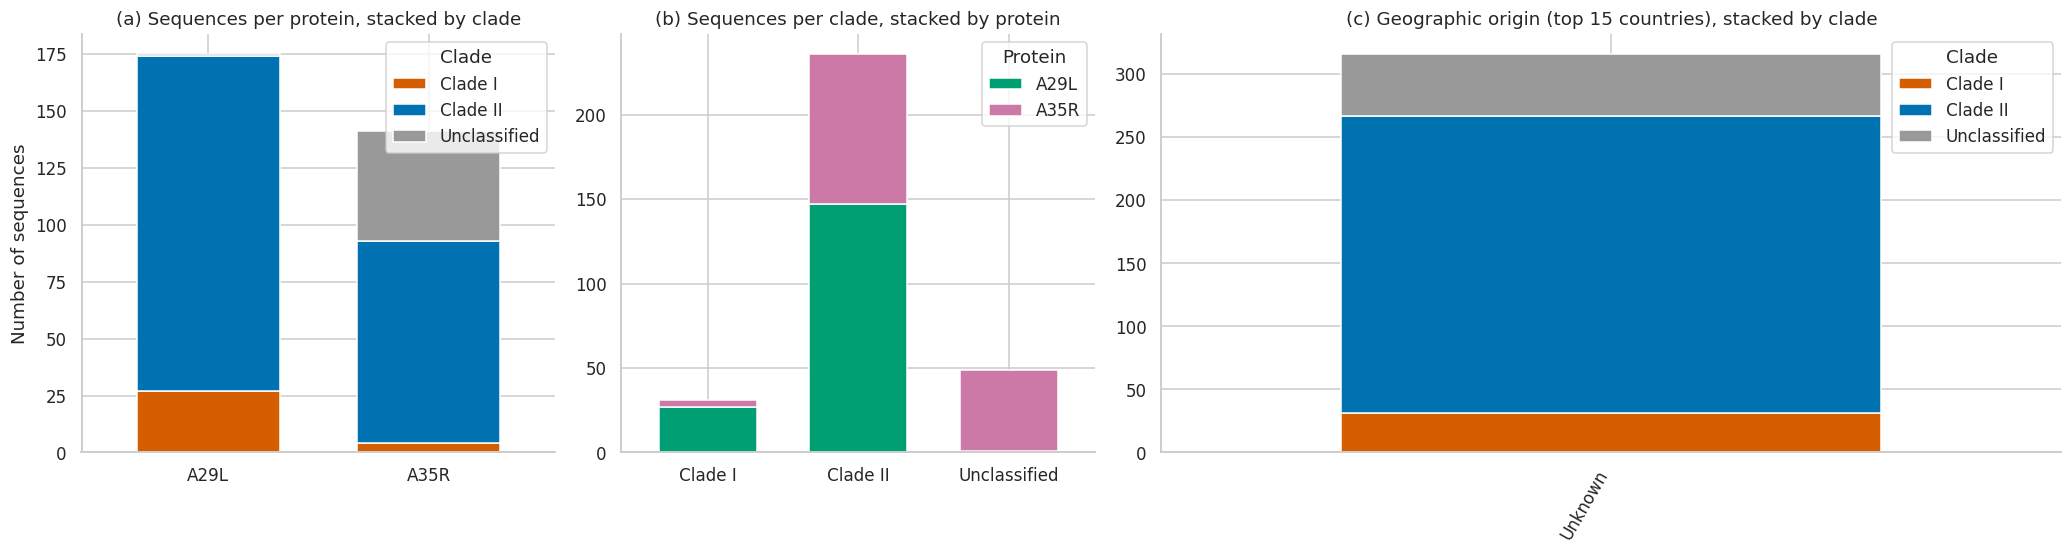

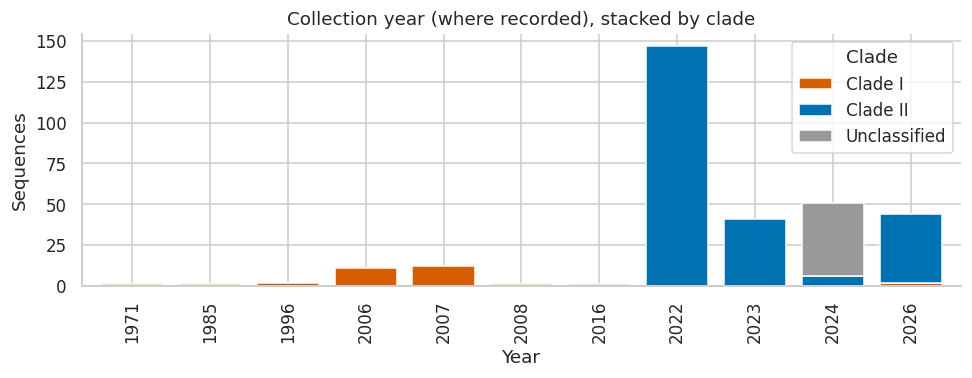

In [ ]:
# ----------------------- Dataset composition plots -----------------------
clade_order = ["Clade I", "Clade II", "Unclassified"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.9]})

ct = pd.crosstab(df.Protein, df.Clade).reindex(columns=clade_order, fill_value=0)       # (a) protein, stacked by clade
ct.plot(kind="bar", stacked=True, ax=axes[0], color=[CLADE_COLORS[c] for c in ct.columns], width=0.65, rot=0)
axes[0].set(title="(a) Sequences per protein, stacked by clade", xlabel="", ylabel="Number of sequences")

ct2 = pd.crosstab(df.Clade, df.Protein).reindex(clade_order, fill_value=0)              # (b) clade, stacked by protein
ct2.plot(kind="bar", stacked=True, ax=axes[1], color=["#009E73", "#CC79A7"], width=0.65, rot=0)
axes[1].set(title="(b) Sequences per clade, stacked by protein", xlabel="", ylabel="")

top = df.Country.value_counts().head(15).index                                         # (c) geography, stacked by clade
ct3 = (pd.crosstab(df[df.Country.isin(top)].Country, df[df.Country.isin(top)].Clade)
       .reindex(columns=clade_order, fill_value=0))
ct3 = ct3.loc[ct3.sum(axis=1).sort_values(ascending=False).index]
ct3.plot(kind="bar", stacked=True, ax=axes[2], color=[CLADE_COLORS[c] for c in ct3.columns], width=0.75)
axes[2].set(title="(c) Geographic origin (top 15 countries), stacked by clade", xlabel="", ylabel="")
axes[2].tick_params(axis="x", rotation=60)
for a in axes[2:]:
    for lbl in a.get_xticklabels():
        lbl.set_ha("right")
fig.tight_layout()
savefig(fig, "fig1_dataset_composition.png")
plt.show()

if df.Year.notna().any():
    fig, ax = plt.subplots(figsize=(9, 3.6))
    yr = pd.crosstab(df.Year.dropna().astype(int), df.Clade[df.Year.notna()]).reindex(columns=clade_order, fill_value=0)
    yr.plot(kind="bar", stacked=True, ax=ax, color=[CLADE_COLORS[c] for c in yr.columns], width=0.8)
    ax.set(title="Collection year (where recorded), stacked by clade", xlabel="Year", ylabel="Sequences")
    fig.tight_layout()
    savefig(fig, "fig2_year_composition.png")
    plt.show()

In [ ]:
# ----------------------- Haplotypes -----------------------
SHORT = {"Clade I": "I", "Clade II": "II"}


def _years(s):
    s = s.dropna()
    return "NA" if len(s) == 0 else (f"{int(s.min())}" if s.min() == s.max() else f"{int(s.min())}-{int(s.max())}")


hap_rows = []
for prot in PROTEINS:
    for clade in CLADES:
        g = df_cls[(df_cls.Protein == prot) & (df_cls.Clade == clade)]
        if g.empty:
            continue
        agg = (g.groupby("Sequence")
                 .agg(Freq=("Accession", "size"),
                      Accessions=("Accession", lambda s: ", ".join(list(s)[:3]) + (" ..." if len(s) > 3 else "")),
                      Countries=("Country", lambda s: ", ".join(sorted(set(s))[:4])),
                      Years=("Year", _years))
                 .reset_index().sort_values(["Freq", "Sequence"], ascending=[False, True]).reset_index(drop=True))
        for i, r in agg.iterrows():
            hap_rows.append({"Haplotype": f"{prot}_{SHORT[clade]}_H{i + 1}", "Protein": prot, "Clade": clade,
                             "Freq": int(r.Freq), "Rel_Freq_in_Clade": r.Freq / len(g), "Length": len(r.Sequence),
                             "Accessions": r.Accessions, "Countries": r.Countries, "Years": r.Years,
                             "Sequence": r.Sequence})
if not hap_rows:
    raise RuntimeError("No clade-classified sequences available. Check Clade_Evidence / metadata in Section 3.")
HAP = pd.DataFrame(hap_rows)
df_cls = df_cls.merge(HAP[["Protein", "Clade", "Sequence", "Haplotype"]], on=["Protein", "Clade", "Sequence"], how="left")

summ = (HAP.groupby(["Protein", "Clade"]).agg(Sequences=("Freq", "sum"), Unique_haplotypes=("Haplotype", "size"),
                                              Top_haplotype_share=("Rel_Freq_in_Clade", "max")).reset_index())
display(summ)
shared = HAP.groupby(["Protein", "Sequence"]).Clade.nunique()
print("Identical sequences shared by BOTH clades:", int((shared > 1).sum()), "(per protein: "
      + ", ".join(f"{p}={int((shared.loc[p] > 1).sum())}" for p in PROTEINS if p in shared.index.get_level_values(0)) + ")")
display(HAP.drop(columns="Sequence").head(15))

,Protein,Clade,Sequences,Unique_haplotypes,Top_haplotype_share
0,A29L,Clade I,27,1,1.000000
1,A29L,Clade II,147,1,1.000000
2,A35R,Clade I,4,1,1.000000
3,A35R,Clade II,89,3,0.651685


Identical sequences shared by BOTH clades: 1 (per protein: A29L=0, A35R=1)


,Haplotype,Protein,Clade,Freq,Rel_Freq_in_Clade,Length,Accessions,Countries,Years
0,A29L_I_H1,A29L,Clade I,27,1.000000,110,"AAY97141.1, AGR34500.1, AGR34690.1 ...",Unknown,1985-2008
1,A29L_II_H1,A29L,Clade II,147,1.000000,110,"WCZ61951.1, WCZ62129.1, WCZ62307.1 ...",Unknown,2022-2023
2,A35R_I_H1,A35R,Clade I,4,1.000000,181,"XYW47091.1, YBZ39477.1, YFT67323.1 ...",Unknown,1971-2026
3,A35R_II_H1,A35R,Clade II,58,0.651685,181,"XEX61951.1, XEX62118.1, XEX62280.1 ...",Unknown,2023-2026
4,A35R_II_H2,A35R,Clade II,30,0.337079,181,"YFI74813.1, YFI74990.1, YFI76299.1 ...",Unknown,2022-2026
5,A35R_II_H3,A35R,Clade II,1,0.011236,181,XOL55170.1,Unknown,2024


In [ ]:
# ----------------------- Physicochemical features -----------------------
PROPS = ["MW_Da", "pI", "GRAVY", "Instability", "Aromaticity", "Charge_pH7.4"]
PROP_LABEL = {"MW_Da": "Molecular weight (Da)", "pI": "Isoelectric point (pI)", "GRAVY": "GRAVY",
              "Instability": "Instability index", "Aromaticity": "Aromaticity", "Charge_pH7.4": "Net charge, pH 7.4"}


def physchem(seq):
    pa = ProteinAnalysis(seq)
    d = {"MW_Da": pa.molecular_weight(), "pI": pa.isoelectric_point(), "GRAVY": pa.gravy(),
         "Instability": pa.instability_index(), "Aromaticity": pa.aromaticity()}
    try:
        d["Charge_pH7.4"] = pa.charge_at_pH(7.4)
    except Exception:
        d["Charge_pH7.4"] = np.nan
    return d


uniq = pd.Series(df.Sequence.unique())
feat = pd.DataFrame([physchem(s) for s in uniq]); feat.insert(0, "Sequence", uniq.values)
df_feat = df.merge(feat, on="Sequence", how="left")                  # all QC-passed sequences (incl. Unclassified)
df_feat_cls = df_feat[df_feat.Clade.isin(CLADES)].copy()
hap_feat = HAP.merge(feat, on="Sequence", how="left")                # one row per haplotype

print("Per-protein, per-clade summary (median [IQR]):")
agg = (df_feat.groupby(["Protein", "Clade"])[PROPS]
       .agg(lambda s: f"{s.median():.3f} [{s.quantile(.25):.3f}-{s.quantile(.75):.3f}]").reset_index())
display(agg)
df_feat.drop(columns="Sequence").to_csv("mpox_physicochemical_features.csv", index=False)

Per-protein, per-clade summary (median [IQR]):


,Protein,Clade,MW_Da,pI,GRAVY,Instability,Aromaticity,Charge_pH7.4
0,A29L,Clade I,12559.096 [12559.096-12559.096],5.758 [5.758-5.758],-0.750 [-0.750--0.750],35.814 [35.814-35.814],0.064 [0.064-0.064],-2.707 [-2.707--2.707]
1,A29L,Clade II,12559.096 [12559.096-12559.096],5.758 [5.758-5.758],-0.750 [-0.750--0.750],32.277 [32.277-32.277],0.064 [0.064-0.064],-2.707 [-2.707--2.707]
2,A29L,Unclassified,12559.096 [12559.096-12559.096],5.758 [5.758-5.758],-0.750 [-0.750--0.750],35.814 [35.814-35.814],0.064 [0.064-0.064],-2.707 [-2.707--2.707]
3,A35R,Clade I,20023.232 [20023.232-20023.232],5.163 [5.163-5.163],-0.316 [-0.316--0.316],41.029 [41.029-41.029],0.083 [0.083-0.083],-5.787 [-5.787--5.787]
4,A35R,Clade II,20023.232 [20023.232-20050.344],5.163 [5.163-5.591],-0.316 [-0.316--0.305],41.029 [41.029-42.337],0.083 [0.083-0.083],-5.787 [-5.787--3.790]
5,A35R,Unclassified,20023.232 [20023.232-20023.232],5.163 [5.163-5.163],-0.316 [-0.316--0.316],41.029 [41.029-41.029],0.083 [0.083-0.083],-5.787 [-5.787--5.787]


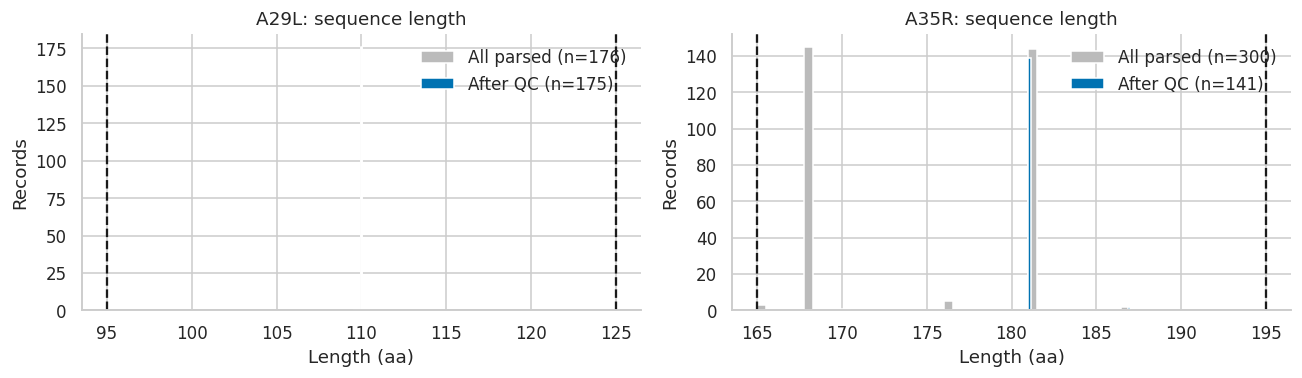

A29L: length range 110-110 aa, median 110; 0 records fell outside the canonical window (95, 125) (truncations or other proteins).
A35R: length range 165-187 aa, median 176; 0 records fell outside the canonical window (165, 195) (truncations or other proteins).


In [ ]:
# ----------------------- EDA 1: sequence length before vs after QC -----------------------
fig, axes = plt.subplots(1, len(PROTEINS), figsize=(6 * len(PROTEINS), 3.6), squeeze=False)
for ax, prot in zip(axes[0], PROTEINS):
    raw = df_parsed[df_parsed.Protein == prot].Length
    ax.hist(raw, bins=40, color="#BBBBBB", label=f"All parsed (n={len(raw)})")
    kept = df[df.Protein == prot].Length
    ax.hist(kept, bins=40, color="#0072B2", label=f"After QC (n={len(kept)})")
    lo, hi = LENGTH_RANGE[prot]
    ax.axvline(lo, ls="--", c="k"); ax.axvline(hi, ls="--", c="k")
    ax.set(title=f"{prot}: sequence length", xlabel="Length (aa)", ylabel="Records"); ax.legend(frameon=False)
fig.tight_layout(); savefig(fig, "fig_eda1_length.png"); plt.show()
for prot in PROTEINS:
    raw = df_parsed[df_parsed.Protein == prot].Length
    if len(raw):
        out = int(((raw < LENGTH_RANGE[prot][0]) | (raw > LENGTH_RANGE[prot][1])).sum())
        print(f"{prot}: length range {raw.min()}-{raw.max()} aa, median {raw.median():.0f}; "
              f"{out} records fell outside the canonical window {LENGTH_RANGE[prot]} (truncations or other proteins).")


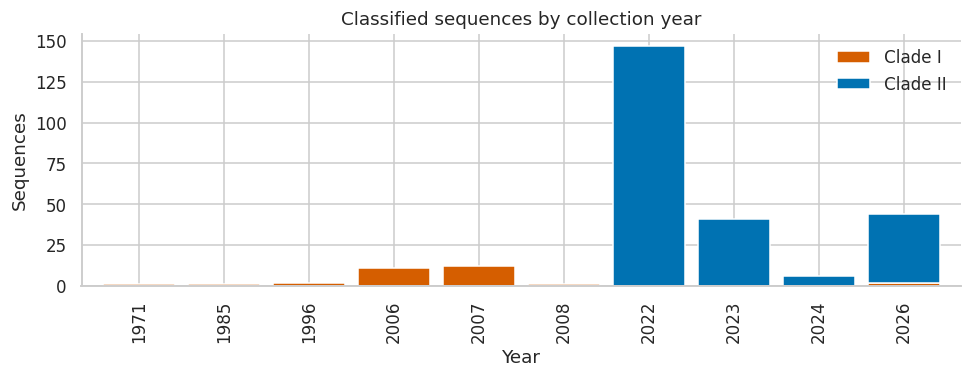

266 of 267 classified records have a collection year (range 1971-2026).
Peak year: 2022 with 147 sequences. Clade II is expected to dominate 2022-2023, so any Clade I vs II difference is partly confounded with time and place of sampling.


In [ ]:
# ----------------------- EDA 2: collection year by clade -----------------------
yr = df_cls.dropna(subset=["Year"]).copy()
if len(yr):
    yr["Year"] = yr.Year.astype(int)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    tab = yr.groupby(["Year", "Clade"]).size().unstack(fill_value=0).reindex(columns=CLADES, fill_value=0)
    tab.plot.bar(stacked=True, ax=ax, color=[CLADE_COLORS[c] for c in CLADES], width=0.85)
    ax.set(title="Classified sequences by collection year", xlabel="Year", ylabel="Sequences"); ax.legend(frameon=False)
    fig.tight_layout(); savefig(fig, "fig_eda2_year.png"); plt.show()
    print(f"{len(yr)} of {len(df_cls)} classified records have a collection year (range {yr.Year.min()}-{yr.Year.max()}).")
    big = tab.sum(axis=1).idxmax()
    print(f"Peak year: {big} with {int(tab.sum(axis=1).max())} sequences. Clade II is expected to dominate 2022-2023, "
          "so any Clade I vs II difference is partly confounded with time and place of sampling.")
else:
    print("No collection years available for classified records.")


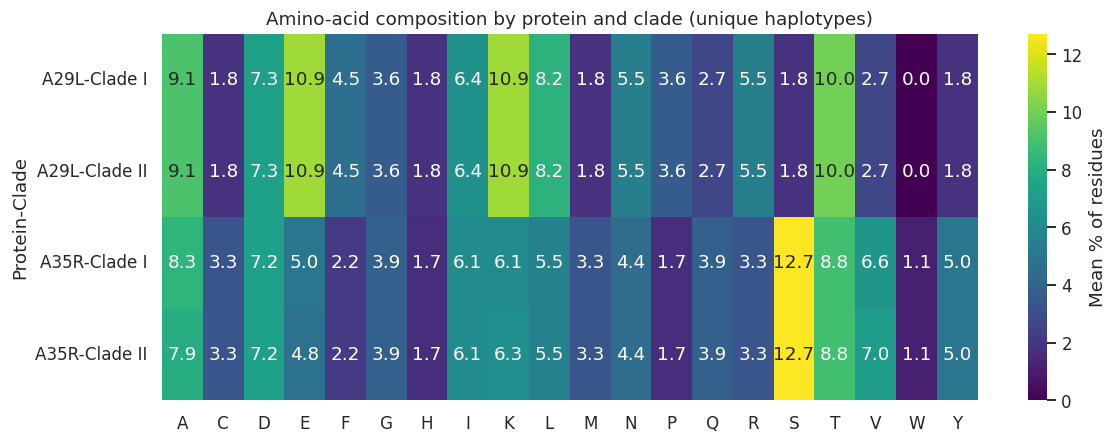

A29L: largest clade difference in composition is A (0.00 percentage points).
A35R: largest clade difference in composition is V (0.37 percentage points).


In [ ]:
# ----------------------- EDA 3: amino-acid composition heatmap -----------------------
AA = list("ACDEFGHIKLMNPQRSTVWY")
def aa_comp(seq):
    return pd.Series({a: seq.count(a) / len(seq) for a in AA})
comp = df_cls.drop_duplicates(["Protein", "Clade", "Sequence"]).copy()
compX = pd.concat([comp[["Protein", "Clade"]].reset_index(drop=True),
                   comp.Sequence.apply(aa_comp).reset_index(drop=True)], axis=1)
grp = compX.groupby(["Protein", "Clade"])[AA].mean() * 100
fig, ax = plt.subplots(figsize=(11, 0.6 * len(grp) + 1.8))
sns.heatmap(grp, annot=True, fmt=".1f", cmap="viridis", cbar_kws={"label": "Mean % of residues"}, ax=ax)
ax.set_title("Amino-acid composition by protein and clade (unique haplotypes)")
fig.tight_layout(); savefig(fig, "fig_eda3_composition.png"); plt.show()
for prot in PROTEINS:
    if (prot, "Clade I") in grp.index and (prot, "Clade II") in grp.index:
        d = (grp.loc[(prot, "Clade I")] - grp.loc[(prot, "Clade II")]).abs()
        print(f"{prot}: largest clade difference in composition is {d.idxmax()} ({d.max():.2f} percentage points).")


A35R: 4 haplotypes, 5 features with variance; PC1+PC2 explain 100% of variance. Point size is haplotype frequency.


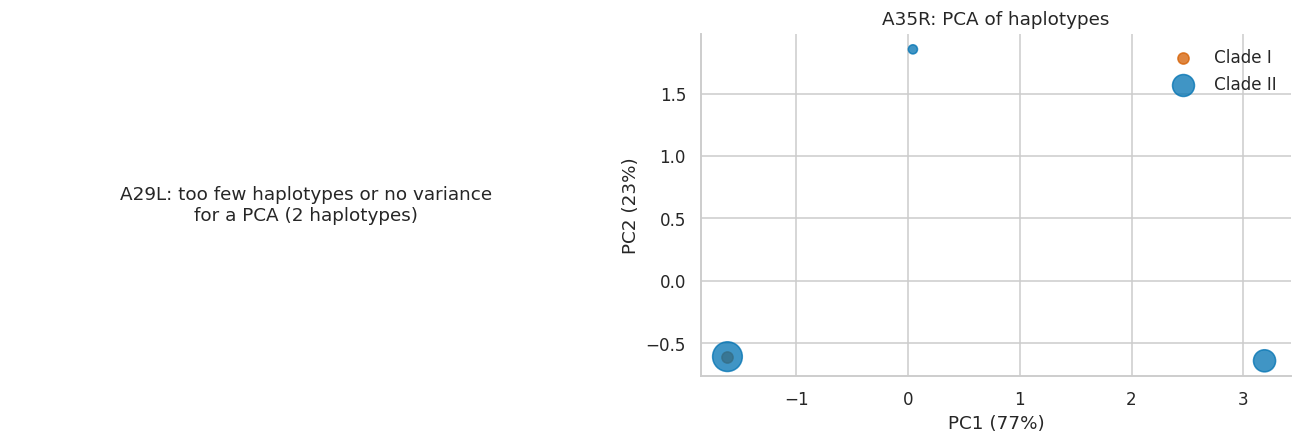

In [ ]:
# ----------------------- EDA 4: PCA of physicochemical features (unique haplotypes) -----------------------
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
fig, axes = plt.subplots(1, len(PROTEINS), figsize=(6 * len(PROTEINS), 4.2), squeeze=False)
for ax, prot in zip(axes[0], PROTEINS):
    g = hap_feat[hap_feat.Protein == prot].dropna(subset=PROPS)
    X = g[PROPS].values
    keep = X.std(axis=0) > 0                                   # drop zero-variance features
    if len(g) < 3 or keep.sum() < 2:
        ax.text(0.5, 0.5, f"{prot}: too few haplotypes or no variance\nfor a PCA ({len(g)} haplotypes)",
                ha="center", va="center"); ax.axis("off"); continue
    Z = StandardScaler().fit_transform(X[:, keep]); p = PCA(n_components=2).fit(Z); XY = p.transform(Z)
    for c in CLADES:
        m = (g.Clade == c).values
        ax.scatter(XY[m, 0], XY[m, 1], s=30 + 6 * g.Freq.values[m], c=CLADE_COLORS[c], alpha=.75, label=c)
    ax.set(title=f"{prot}: PCA of haplotypes", xlabel=f"PC1 ({100*p.explained_variance_ratio_[0]:.0f}%)",
           ylabel=f"PC2 ({100*p.explained_variance_ratio_[1]:.0f}%)"); ax.legend(frameon=False)
    print(f"{prot}: {len(g)} haplotypes, {int(keep.sum())} features with variance; PC1+PC2 explain "
          f"{100*p.explained_variance_ratio_[:2].sum():.0f}% of variance. Point size is haplotype frequency.")
fig.tight_layout(); savefig(fig, "fig_eda4_pca.png"); plt.show()


In [ ]:
# ----------------------- Stage 4 checkpoint (fail fast) -----------------------
assert len(HAP) > 0, "No haplotypes were built."
assert np.isfinite(df_feat_cls[PROPS].to_numpy(dtype=float)).all(), "NaN/inf in physicochemical features."
assert (df_feat_cls.MW_Da > 5_000).all(), "Implausible molecular weights: sequences may be truncated."
stage_ok(4, 3)


✔ Stage 4 checkpoint passed (3 checks).


**Reading the EDA.** (1) Records outside the canonical length window are truncations or other proteins and were removed in Stage 3. (2) The year plot shows sampling intensity, not incidence. (3) A clade difference in amino-acid composition larger than about one percentage point would be notable for a ~110-181 aa protein; smaller shifts are single-residue changes. (4) In the PCA, separation by clade means a systematic physicochemical difference. Overlap or a single point per clade means the descriptors cannot distinguish clades. **Because the PCA is built on very few haplotypes, treat it as descriptive only.**

<a id="stage5"></a>
## Stage 5: Core Analysis  (a) Global/Local Alignment & Clade-Defining Mutation Analysis  *(KDD phase 4: Data Mining)*

**Method**

1. **Haplotypes.** Identical sequences within a protein and clade collapse into one haplotype with a frequency count. IDs look like `A29L_I_H1` (the most frequent Clade I haplotype of A29L).
2. **Reference sequences.** The modal (most frequent) haplotype of each clade is its canonical reference.
3. **Pairwise alignment** with `Bio.Align.PairwiseAligner`: *global* (Needleman-Wunsch) and *local* (Smith-Waterman), BLOSUM62, gap open -10 and extend -0.5. This compares the Clade I reference with the Clade II reference.
4. **Multiple alignment (star alignment).** Every haplotype is globally aligned to the Clade I reference and projected into its coordinates. This is a sound approximation for near-identical orthologs. Insertions relative to the reference are dropped, and all numbering follows the Clade I reference.
5. **Shannon entropy** per column, $H = -\sum_i p_i \log_2 p_i$ over the 20 amino acids (gaps excluded, weighted by haplotype frequency). $H = 0$ means fully conserved and $H_{max}=\log_2 20 \approx 4.32$ bits.
6. **Mutation table.** Every variable position is listed. A substitution is *conservative* if its BLOSUM62 score is greater than 0, and *non-conservative* otherwise. The table also gives the change in net charge (K/R = +1, D/E = -1) and in Kyte-Doolittle hydropathy.

In [ ]:
# ----------------------- Pairwise global & local alignment of clade references -----------------------
BLOSUM62 = substitution_matrices.load("BLOSUM62")


def make_aligner(mode="global"):
    a = Align.PairwiseAligner()
    a.mode = mode
    a.substitution_matrix = BLOSUM62
    a.open_gap_score = -10.0
    a.extend_gap_score = -0.5
    return a


def aln_stats(aln, ref, qry):
    """Identity over alignment columns (global) from aligned blocks."""
    blocks = list(zip(aln.aligned[0], aln.aligned[1]))
    aligned_cols = sum(e - s for (s, e), _ in blocks)
    matches = sum(sum(ref[i] == qry[j] for i, j in zip(range(rs, re_), range(qs, qe)))
                  for (rs, re_), (qs, qe) in blocks)
    cols = aligned_cols + (len(ref) - aligned_cols) + (len(qry) - aligned_cols)
    return matches, aligned_cols, cols


REFS = {}                      # (protein, clade) -> (haplotype id, sequence)
for prot in PROTEINS:
    for clade in CLADES:
        g = HAP[(HAP.Protein == prot) & (HAP.Clade == clade)]
        if not g.empty:
            REFS[(prot, clade)] = (g.iloc[0].Haplotype, g.iloc[0].Sequence)

g_al, l_al = make_aligner("global"), make_aligner("local")
rows = []
for prot in PROTEINS:
    if (prot, "Clade I") not in REFS or (prot, "Clade II") not in REFS:
        print(f"{prot}: both a Clade I and a Clade II reference are required - skipping pairwise comparison.")
        continue
    (idI, sI), (idII, sII) = REFS[(prot, "Clade I")], REFS[(prot, "Clade II")]
    ga = g_al.align(sI, sII)[0]
    la = l_al.align(sI, sII)[0]
    m, ac, cols = aln_stats(ga, sI, sII)
    lm, lac, _ = aln_stats(la, sI, sII)
    rows.append({"Protein": prot, "Clade I ref": idI, "Clade II ref": idII,
                 "Global score": g_al.score(sI, sII), "Global identity %": 100 * m / cols,
                 "Global mismatches": ac - m, "Local score": l_al.score(sI, sII),
                 "Local aligned length": lac, "Local identity %": 100 * lm / max(lac, 1)})
    print(f"=== {prot}: global alignment of {idI} (target) vs {idII} (query) ===")
    print(ga)
if rows:
    display(pd.DataFrame(rows).round(2))

=== A29L: global alignment of A29L_I_H1 (target) vs A29L_II_H1 (query) ===
target            0 MDGTLFPGDDDLAIPATEFFSTKAAKNPETKREAIVKAYGDDNEETLKQRLTNLEKKITN
                  0 ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
query             0 MDGTLFPGDDDLAIPATEFFSTKAAKNPETKREAIVKAYGDDNEETLKQRLTNLEKKITN

target           60 ITTKFEQIEKCCKHNDEVLFRLENHAETLRAAMISLAKKIDVQTGRRPYE 110
                 60 |||||||||||||.||||||||||||||||||||||||||||||||.||| 110
query            60 ITTKFEQIEKCCKRNDEVLFRLENHAETLRAAMISLAKKIDVQTGRHPYE 110

=== A35R: global alignment of A35R_I_H1 (target) vs A35R_II_H1 (query) ===
target            0 MMTPENDEEQTSVFSATVYGDKIQGKNKRKRVIGLCIRISMVISLLSMITMSAFLIVRLN
                  0 ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
query             0 MMTPENDEEQTSVFSATVYGDKIQGKNKRKRVIGLCIRISMVISLLSMITMSAFLIVRLN

target           60 QCMSANEAAITDSAVAVAAASSTHRKVASSTTQYDHKESCNGLYYQGSCYILHSDYKSFE
                 60 |||||||||||||||||||||||||||||||||||

,Protein,Clade I ref,Clade II ref,Global score,Global identity %,Global mismatches,Local score,Local aligned length,Local identity %
0,A29L,A29L_I_H1,A29L_II_H1,555.0,98.18,2,555.0,110,98.18
1,A35R,A35R_I_H1,A35R_II_H1,935.0,100.00,0,935.0,181,100.00


In [ ]:
# ----------------------- Star MSA, Shannon entropy, mutation table -----------------------
def project_to_reference(ref, seq, aligner):
    """Global-align seq to ref and return a string of len(ref) ('-' = deletion; insertions dropped)."""
    if seq == ref:
        return ref
    aln = aligner.align(ref, seq)[0]
    out = ["-"] * len(ref)
    for (rs, re_), (qs, qe) in zip(aln.aligned[0], aln.aligned[1]):
        out[rs:re_] = list(seq[qs:qe])
    return "".join(out)


def shannon(col, w):
    keep = col != "-"
    if not keep.any():
        return 0.0
    _, inv = np.unique(col[keep], return_inverse=True)
    p = np.bincount(inv, weights=w[keep])
    p = p / p.sum()
    return float(-(p * np.log2(p)).sum())


CHARGE = {"K": 1, "R": 1, "D": -1, "E": -1}
MUT_COLS = ["Protein", "Position", "Ref_residue", "Clade_I_residue", "Clade_I_freq", "Clade_II_residue",
            "Clade_II_freq", "All_variants", "Category", "Substitution", "Substitution_type", "BLOSUM62",
            "Delta_charge", "Delta_KD_hydropathy", "Entropy_bits"]
MAJ_FIXED = 0.90          # a clade's majority residue must reach this frequency to call a position "fixed"


def build_alignment(prot):
    haps = HAP[HAP.Protein == prot].reset_index(drop=True)
    ref_clade = "Clade I" if (prot, "Clade I") in REFS else "Clade II"
    ref_id, ref_seq = REFS[(prot, ref_clade)]
    M = np.array([list(project_to_reference(ref_seq, s, g_al)) for s in haps.Sequence])
    w = haps.Freq.values.astype(float)
    clades = haps.Clade.values
    L = M.shape[1]
    H_all = np.array([shannon(M[:, j], w) for j in range(L)])
    H_cl = {c: np.array([shannon(M[clades == c][:, j], w[clades == c]) for j in range(L)])
            for c in CLADES if (clades == c).any()}

    recs = []
    for j in range(L):
        col = M[:, j]
        if len(set(col)) < 2:
            continue
        info = {}
        for c in CLADES:
            msk = clades == c
            if not msk.any():
                continue
            tot = w[msk].sum()
            cnt = {}
            for aa, ww in zip(col[msk], w[msk]):
                cnt[aa] = cnt.get(aa, 0) + ww
            top, topn = max(cnt.items(), key=lambda kv: kv[1])
            info[c] = (top, topn / tot, cnt)
        allcnt = {}
        for aa, ww in zip(col, w):
            allcnt[aa] = allcnt.get(aa, 0) + ww
        a_I = info.get("Clade I", (None, np.nan, {}))
        a_II = info.get("Clade II", (None, np.nan, {}))
        if a_I[0] is not None and a_II[0] is not None and a_I[0] != a_II[0]:
            cat = "Clade-defining (fixed)" if min(a_I[1], a_II[1]) >= MAJ_FIXED else "Clade-biased (majority differs)"
            a, b = a_I[0], a_II[0]
        else:
            cat = "Intra-clade polymorphism"
            ranked = sorted(allcnt.items(), key=lambda kv: -kv[1])
            a, b = ranked[0][0], ranked[1][0]
        if a == "-" or b == "-":
            stype, bl, dq, dh = "Indel", np.nan, np.nan, np.nan
        else:
            bl = BLOSUM62[a][b]
            stype = "Conservative" if bl > 0 else "Non-conservative"
            dq = CHARGE.get(b, 0) - CHARGE.get(a, 0)
            dh = round(KYTE_DOOLITTLE[b] - KYTE_DOOLITTLE[a], 2)
        recs.append({"Protein": prot, "Position": j + 1, "Ref_residue": ref_seq[j],
                     "Clade_I_residue": a_I[0], "Clade_I_freq": round(a_I[1], 3) if a_I[0] else np.nan,
                     "Clade_II_residue": a_II[0], "Clade_II_freq": round(a_II[1], 3) if a_II[0] else np.nan,
                     "All_variants": ", ".join(f"{k}:{int(v)}" for k, v in sorted(allcnt.items(), key=lambda kv: -kv[1])),
                     "Category": cat, "Substitution": f"{a}->{b}", "Substitution_type": stype, "BLOSUM62": bl,
                     "Delta_charge": dq, "Delta_KD_hydropathy": dh, "Entropy_bits": round(H_all[j], 3)})
    return {"ref_id": ref_id, "ref_clade": ref_clade, "ref_seq": ref_seq, "haps": haps, "M": M, "w": w,
            "clades": clades, "H_all": H_all, "H_cl": H_cl, "mut": pd.DataFrame(recs, columns=MUT_COLS)}


ALN = {p: build_alignment(p) for p in PROTEINS if (HAP.Protein == p).any()}
for p, a in ALN.items():
    print(f"{p}: {a['M'].shape[0]} haplotypes aligned to {a['ref_id']} (length {a['M'].shape[1]}); "
          f"{len(a['mut'])} variable positions; {int((a['H_all'] > 0).sum())} columns with entropy > 0")

MUT = pd.concat([a["mut"] for a in ALN.values()], ignore_index=True) if ALN else pd.DataFrame()
print("\n=== Mutation summary table: every variable residue position ===")
display(MUT)
if len(MUT):
    display(MUT.groupby(["Protein", "Category", "Substitution_type"]).size().rename("positions").reset_index())
    MUT.to_csv("mpox_mutation_summary.csv", index=False)

A29L: 2 haplotypes aligned to A29L_I_H1 (length 110); 2 variable positions; 2 columns with entropy > 0
A35R: 4 haplotypes aligned to A35R_I_H1 (length 181); 3 variable positions; 3 columns with entropy > 0

=== Mutation summary table: every variable residue position ===


,Protein,Position,Ref_residue,Clade_I_residue,Clade_I_freq,Clade_II_residue,Clade_II_freq,All_variants,Category,Substitution,Substitution_type,BLOSUM62,Delta_charge,Delta_KD_hydropathy,Entropy_bits
0,A29L,74,H,H,1.0,R,1.000,"R:147, H:27",Clade-defining (fixed),H->R,Non-conservative,0.0,1,-1.3,0.623
1,A29L,107,R,R,1.0,H,1.000,"H:147, R:27",Clade-defining (fixed),R->H,Non-conservative,0.0,-1,1.3,0.623
2,A35R,67,E,E,1.0,E,0.663,"E:63, K:30",Intra-clade polymorphism,E->K,Conservative,1.0,2,-0.4,0.907
3,A35R,88,A,A,1.0,A,0.663,"A:63, V:30",Intra-clade polymorphism,A->V,Non-conservative,0.0,0,2.4,0.907
4,A35R,128,A,A,1.0,A,0.989,"A:92, V:1",Intra-clade polymorphism,A->V,Non-conservative,0.0,0,2.4,0.086


,Protein,Category,Substitution_type,positions
0,A29L,Clade-defining (fixed),Non-conservative,2
1,A35R,Intra-clade polymorphism,Conservative,1
2,A35R,Intra-clade polymorphism,Non-conservative,2


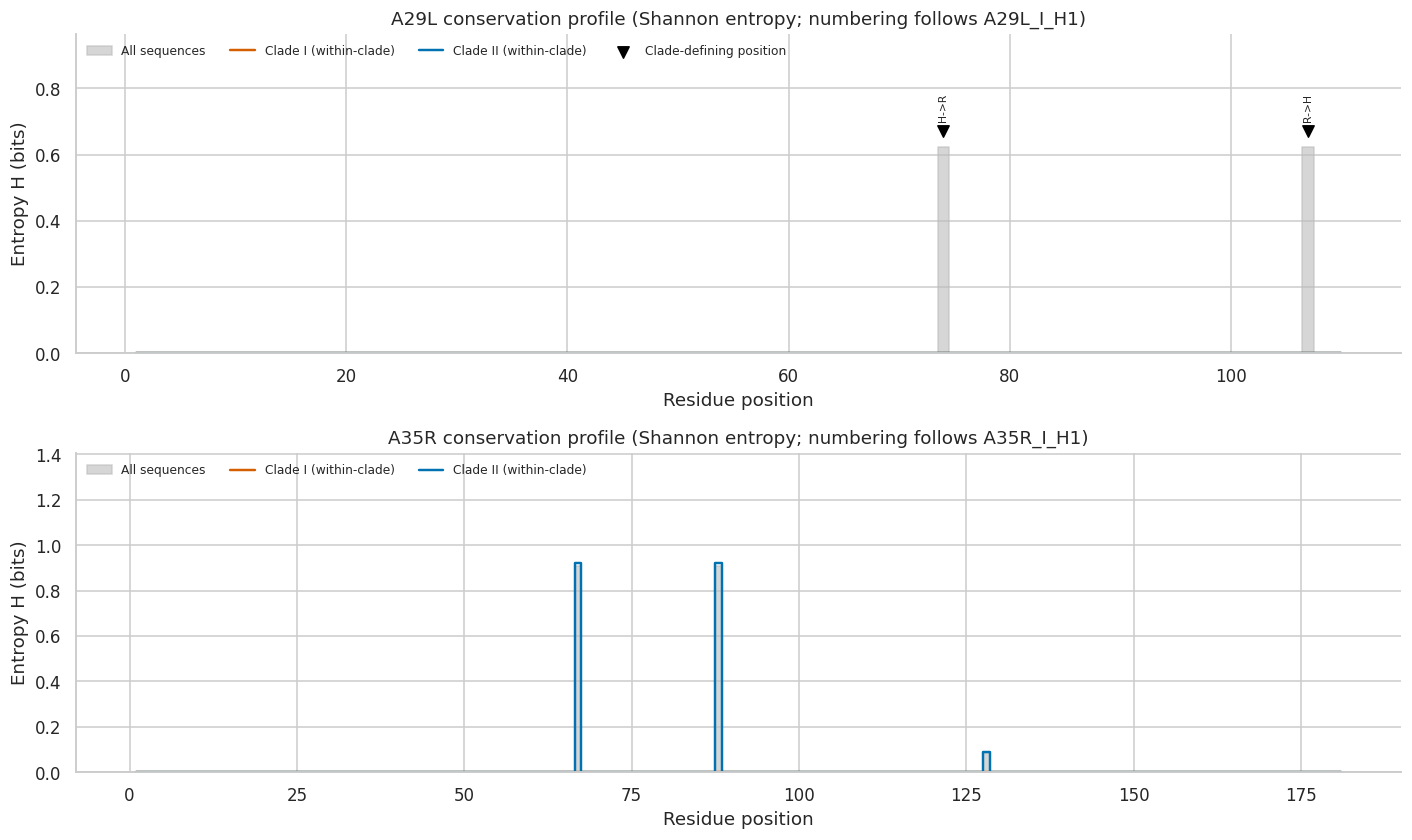

In [ ]:
# ----------------------- Shannon entropy conservation profile -----------------------
fig, axes = plt.subplots(len(ALN), 1, figsize=(13, 3.9 * len(ALN)), squeeze=False)
for ax, (prot, a) in zip(axes[:, 0], ALN.items()):
    pos = np.arange(1, a["M"].shape[1] + 1)
    ax.fill_between(pos, a["H_all"], step="mid", color="#bbbbbb", alpha=0.6, label="All sequences")
    for c, h in a["H_cl"].items():
        ax.plot(pos, h, drawstyle="steps-mid", lw=1.6, color=CLADE_COLORS[c], label=f"{c} (within-clade)")
    m = a["mut"]
    cd = m[m.Category == "Clade-defining (fixed)"]
    if len(cd):
        ymax = max(a["H_all"].max(), 0.5)
        ax.scatter(cd.Position, [ymax * 1.08] * len(cd), marker="v", s=55, color="black", zorder=5,
                   label="Clade-defining position")
        for _, r in cd.iterrows():
            ax.annotate(r.Substitution, (r.Position, ymax * 1.08), xytext=(0, 7), textcoords="offset points",
                        ha="center", fontsize=7, rotation=90)
    ax.set(title=f"{prot} conservation profile (Shannon entropy; numbering follows {a['ref_id']})",
           xlabel="Residue position", ylabel="Entropy H (bits)", ylim=(0, max(a["H_all"].max(), 0.5) * 1.55))
    ax.legend(loc="upper left", ncol=4, fontsize=8, frameon=False)
fig.tight_layout()
savefig(fig, "fig3_entropy_profiles.png")
plt.show()

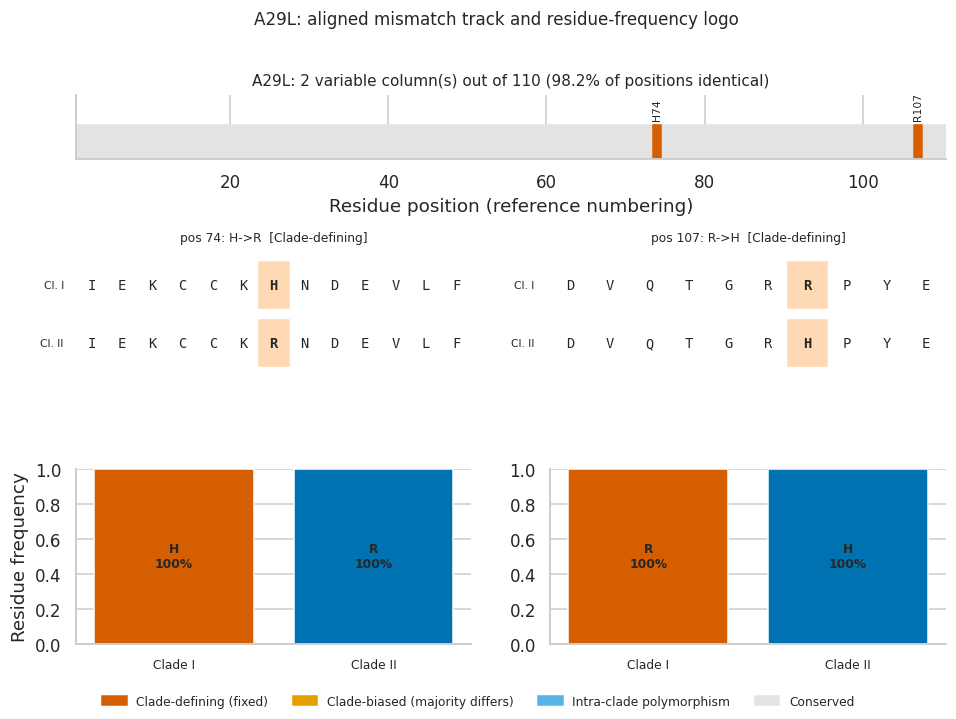

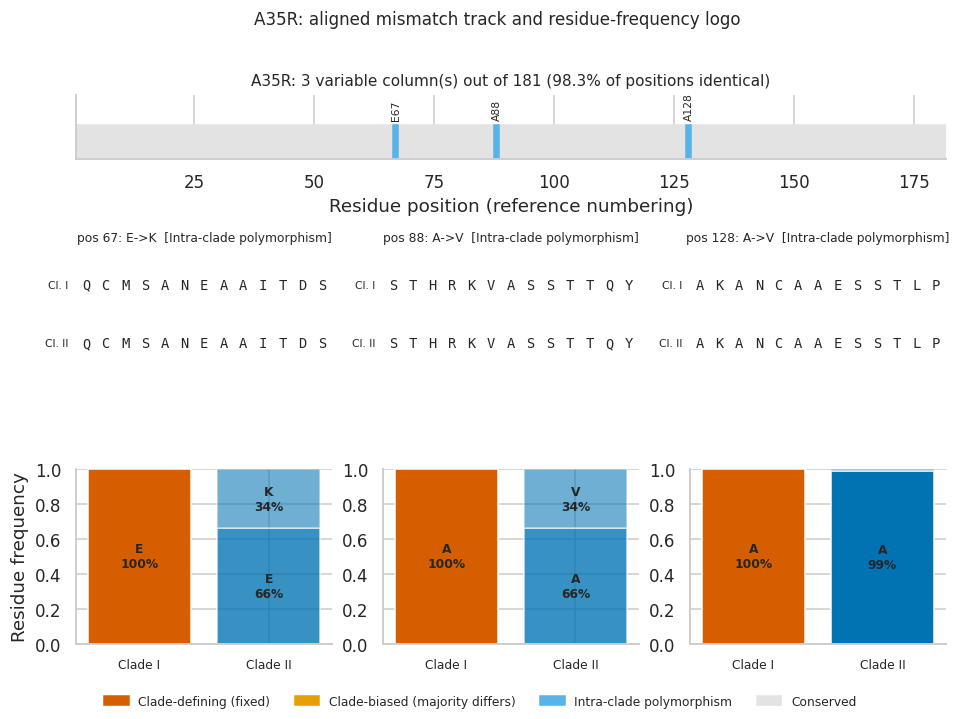

In [ ]:
# ----------------------- Stage 5: aligned mismatch track + mini sequence logo -----------------------
from matplotlib.patches import Rectangle
CAT_COL = {"Clade-defining (fixed)": "#D55E00", "Clade-biased (majority differs)": "#E69F00", "Intra-clade polymorphism": "#56B4E9"}


def mismatch_track(prot, ctx=6, max_zoom=4):
    a = ALN[prot]; ref, M, w, cl, mut = a["ref_seq"], a["M"], a["w"], a["clades"], a["mut"].copy()
    L = len(ref)
    if mut.empty:
        print(f"{prot}: no variable columns, so the mismatch track is just a conserved bar (all {L} positions identical).")
    order = {"Clade-defining (fixed)": 0, "Clade-biased (majority differs)": 1, "Intra-clade polymorphism": 2}
    zoom = mut.assign(_o=mut.Category.map(order)).sort_values(["_o", "Entropy_bits"], ascending=[True, False]).head(max_zoom)
    ncol = max(1, len(zoom))
    fig = plt.figure(figsize=(3.4 * max(ncol, 3), 6.4))
    gs = fig.add_gridspec(3, ncol, height_ratios=[0.55, 1.1, 1.5], hspace=0.75)
    ax = fig.add_subplot(gs[0, :])
    ax.add_patch(Rectangle((0.5, 0), L, 1, color="#E3E3E3"))
    for _, r in mut.iterrows():
        ax.add_patch(Rectangle((r.Position - 0.5, 0), 1, 1, color=CAT_COL.get(r.Category, "k")))
        ax.text(r.Position, 1.15, f"{r.Ref_residue}{int(r.Position)}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xlim(0.5, L + 0.5); ax.set_ylim(0, 1.9); ax.set_yticks([])
    ax.set_xlabel("Residue position (reference numbering)")
    ax.set_title(f"{prot}: {len(mut)} variable column(s) out of {L} ({100 * (1 - len(mut) / L):.1f}% of positions identical)", fontsize=10, pad=6)
    fig.legend(handles=[Patch(color=c, label=k) for k, c in CAT_COL.items()] + [Patch(color="#E3E3E3", label="Conserved")],
               loc="lower center", fontsize=8, frameon=False, ncol=4)
    for k, (_, r) in enumerate(zoom.iterrows()):
        p = int(r.Position) - 1
        lo, hi = max(0, p - ctx), min(L, p + ctx + 1)
        axz = fig.add_subplot(gs[1, k]); axz.set_xlim(lo - 0.5, hi - 0.5); axz.set_ylim(-0.6, 1.6); axz.axis("off")
        cons = {}
        for ci, c in enumerate(CLADES):
            msk = cl == c
            if not msk.any():
                continue
            cons[c] = ["".join(M[msk][:, j]) and max(set(M[msk][:, j]), key=lambda x: w[msk][M[msk][:, j] == x].sum()) for j in range(lo, hi)]
        for ci, c in enumerate(cons):
            y = 1.0 - ci
            axz.text(lo - 0.9, y, c.replace("Clade ", "Cl. "), ha="right", va="center", fontsize=7)
            for jj, aa in enumerate(cons[c]):
                other = [cons[o][jj] for o in cons if o != c]
                diff = any(aa != o for o in other)
                if diff:
                    axz.add_patch(Rectangle((lo + jj - 0.5, y - 0.4), 1, 0.8, color="#FFD9B3"))
                axz.text(lo + jj, y, aa, ha="center", va="center", family="monospace", fontsize=9, fontweight="bold" if diff else "normal")
        axz.set_title(f"pos {int(r.Position)}: {r.Substitution}  [{r.Category.split(' (')[0]}]", fontsize=8)
        axl = fig.add_subplot(gs[2, k])
        bottoms = {}
        for ci, c in enumerate(CLADES):
            msk = cl == c
            if not msk.any():
                continue
            col = M[msk][:, p]; ww = w[msk]; tot = ww.sum(); b = 0.0
            for aa in sorted(set(col), key=lambda x: -ww[col == x].sum()):
                fr = ww[col == aa].sum() / tot
                axl.bar(ci, fr, bottom=b, color=CLADE_COLORS[c], alpha=0.35 + 0.65 * fr, edgecolor="white")
                if fr > 0.06:
                    axl.text(ci, b + fr / 2, f"{aa}\n{fr:.0%}", ha="center", va="center", fontsize=8, fontweight="bold")
                b += fr
        axl.set_xticks(range(len(CLADES))); axl.set_xticklabels(["Clade I", "Clade II"], fontsize=8)
        axl.set_ylim(0, 1); axl.set_ylabel("Residue frequency" if k == 0 else "")
    fig.suptitle(f"{prot}: aligned mismatch track and residue-frequency logo", y=1.0, fontsize=11)
    fig.subplots_adjust(bottom=0.1)
    savefig(fig, f"fig_mismatch_track_{prot}.png"); plt.show()


for _p in ALN:
    mismatch_track(_p)


### Stage 5 (b): Physicochemical & Antigenic Property Profiling  *(KDD phases 3 and 5)*

`Bio.SeqUtils.ProtParam.ProteinAnalysis` gives, for every sequence:

| Feature | Meaning |
|---|---|
| **MW (Da)** | Molecular weight |
| **pI** | Isoelectric point (surface charge behaviour) |
| **GRAVY** | Grand Average of Hydropathicity (positive = hydrophobic) |
| **Instability index** | Values above 40 predict an unstable protein in vitro |
| **Aromaticity** | Fraction of F, W and Y |
| **Net charge at pH 7.4** | Extra feature (when supported by your Biopython version) |

Clade I and Clade II are compared with a **two-sided Mann-Whitney U test**. The rank-biserial correlation $r = 2U/(n_1 n_2) - 1$ is the effect size; $r>0$ means Clade I values tend to be larger. Because identical sequences are heavily duplicated in outbreak data, which inflates $n$, each test is also run on **unique haplotypes only**. Bonferroni correction is applied across all tests within each level.

In [ ]:
# ----------------------- Mann-Whitney U tests -----------------------
def mwu_table(data, level):
    rows = []
    for prot in PROTEINS:
        for prop in PROPS:
            x = data[(data.Protein == prot) & (data.Clade == "Clade I")][prop].dropna().values
            y = data[(data.Protein == prot) & (data.Clade == "Clade II")][prop].dropna().values
            if len(x) < 2 or len(y) < 2:
                rows.append({"Level": level, "Protein": prot, "Property": prop, "n_I": len(x), "n_II": len(y)})
                continue
            try:
                U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
            except ValueError:                       # all values identical
                U, p = len(x) * len(y) / 2, 1.0
            rows.append({"Level": level, "Protein": prot, "Property": prop, "n_I": len(x), "n_II": len(y),
                         "Median_I": np.median(x), "Median_II": np.median(y),
                         "U": U, "p_value": p, "rank_biserial_r": 2 * U / (len(x) * len(y)) - 1})
    t = pd.DataFrame(rows)
    if "p_value" in t:
        k = t.p_value.notna().sum()
        t["p_Bonferroni"] = (t.p_value * k).clip(upper=1.0)
        t["Significant (p<0.05)"] = t.p_Bonferroni < 0.05
    return t


MWU = pd.concat([mwu_table(df_feat_cls, "Sequence-level"), mwu_table(hap_feat, "Haplotype-level")], ignore_index=True)
display(MWU.round(5))
MWU.to_csv("mpox_mannwhitney_results.csv", index=False)
sig = MWU[MWU.get("Significant (p<0.05)", pd.Series(False, index=MWU.index)) == True]
print("\nProperties differing significantly between clades after Bonferroni correction:")
print(sig[["Level", "Protein", "Property", "Median_I", "Median_II", "p_Bonferroni"]].to_string(index=False) if len(sig)
      else "  none (clades are physicochemically indistinguishable for these global descriptors)")

,Level,Protein,Property,n_I,n_II,Median_I,Median_II,U,p_value,rank_biserial_r,p_Bonferroni,Significant (p<0.05)
0,Sequence-level,A29L,MW_Da,27,147,12559.09640,12559.09640,1984.5,1.00000,0.00000,1.0,False
1,Sequence-level,A29L,pI,27,147,5.75798,5.75798,1984.5,1.00000,0.00000,1.0,False
2,Sequence-level,A29L,GRAVY,27,147,-0.75000,-0.75000,1984.5,1.00000,0.00000,1.0,False
3,Sequence-level,A29L,Instability,27,147,35.81364,32.27727,3969.0,0.00000,1.00000,0.0,True
4,Sequence-level,A29L,Aromaticity,27,147,0.06364,0.06364,1984.5,1.00000,0.00000,1.0,False
5,Sequence-level,A29L,Charge_pH7.4,27,147,-2.70698,-2.70698,1984.5,1.00000,0.00000,1.0,False
6,Sequence-level,A35R,MW_Da,4,89,20023.23240,20023.23240,116.0,0.15486,-0.34831,1.0,False
7,Sequence-level,A35R,pI,4,89,5.16333,5.16333,118.0,0.16407,-0.33708,1.0,False
8,Sequence-level,A35R,GRAVY,4,89,-0.31602,-0.31602,116.0,0.15486,-0.34831,1.0,False
9,Sequence-level,A35R,Instability,4,89,41.02873,41.02873,118.0,0.16407,-0.33708,1.0,False



Properties differing significantly between clades after Bonferroni correction:
         Level Protein    Property  Median_I  Median_II  p_Bonferroni
Sequence-level    A29L Instability 35.813636  32.277273  2.052042e-38


In [ ]:
# ----------------------- Stage 5: Benjamini-Hochberg FDR (supplements Bonferroni) -----------------------
def bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    adj = np.empty(n); run = 1.0
    for rank, idx in zip(range(n, 0, -1), o[::-1]):
        run = min(run, p[idx] * n / rank); adj[idx] = run
    return adj
if "p_value" in MWU:
    MWU["p_BH_FDR"] = np.nan
    for lvl in MWU.Level.unique():
        m = (MWU.Level == lvl) & MWU.p_value.notna()
        if m.any():
            MWU.loc[m, "p_BH_FDR"] = bh(MWU.loc[m, "p_value"])
    MWU.to_csv("mpox_mannwhitney_results.csv", index=False)
    show = MWU[MWU.p_value.notna()][["Level", "Protein", "Property", "n_I", "n_II", "Median_I", "Median_II",
                                     "rank_biserial_r", "p_value", "p_Bonferroni", "p_BH_FDR"]]
    display(show.round(5))
    print("Level-wise note: haplotype-level tests use very small n (often 1-3 haplotypes per clade); "
          "'test n/a' means fewer than 2 observations in a group, so no p-value exists. This is not evidence of no difference.")
else:
    print("No testable comparisons (too few observations per clade).")


,Level,Protein,Property,n_I,n_II,Median_I,Median_II,rank_biserial_r,p_value,p_Bonferroni,p_BH_FDR
0,Sequence-level,A29L,MW_Da,27,147,12559.09640,12559.09640,0.00000,1.00000,1.0,1.00000
1,Sequence-level,A29L,pI,27,147,5.75798,5.75798,0.00000,1.00000,1.0,1.00000
2,Sequence-level,A29L,GRAVY,27,147,-0.75000,-0.75000,0.00000,1.00000,1.0,1.00000
3,Sequence-level,A29L,Instability,27,147,35.81364,32.27727,1.00000,0.00000,0.0,0.00000
4,Sequence-level,A29L,Aromaticity,27,147,0.06364,0.06364,0.00000,1.00000,1.0,1.00000
5,Sequence-level,A29L,Charge_pH7.4,27,147,-2.70698,-2.70698,0.00000,1.00000,1.0,1.00000
6,Sequence-level,A35R,MW_Da,4,89,20023.23240,20023.23240,-0.34831,0.15486,1.0,0.32814
7,Sequence-level,A35R,pI,4,89,5.16333,5.16333,-0.33708,0.16407,1.0,0.32814
8,Sequence-level,A35R,GRAVY,4,89,-0.31602,-0.31602,-0.34831,0.15486,1.0,0.32814
9,Sequence-level,A35R,Instability,4,89,41.02873,41.02873,-0.33708,0.16407,1.0,0.32814


Level-wise note: haplotype-level tests use very small n (often 1-3 haplotypes per clade); 'test n/a' means fewer than 2 observations in a group, so no p-value exists. This is not evidence of no difference.


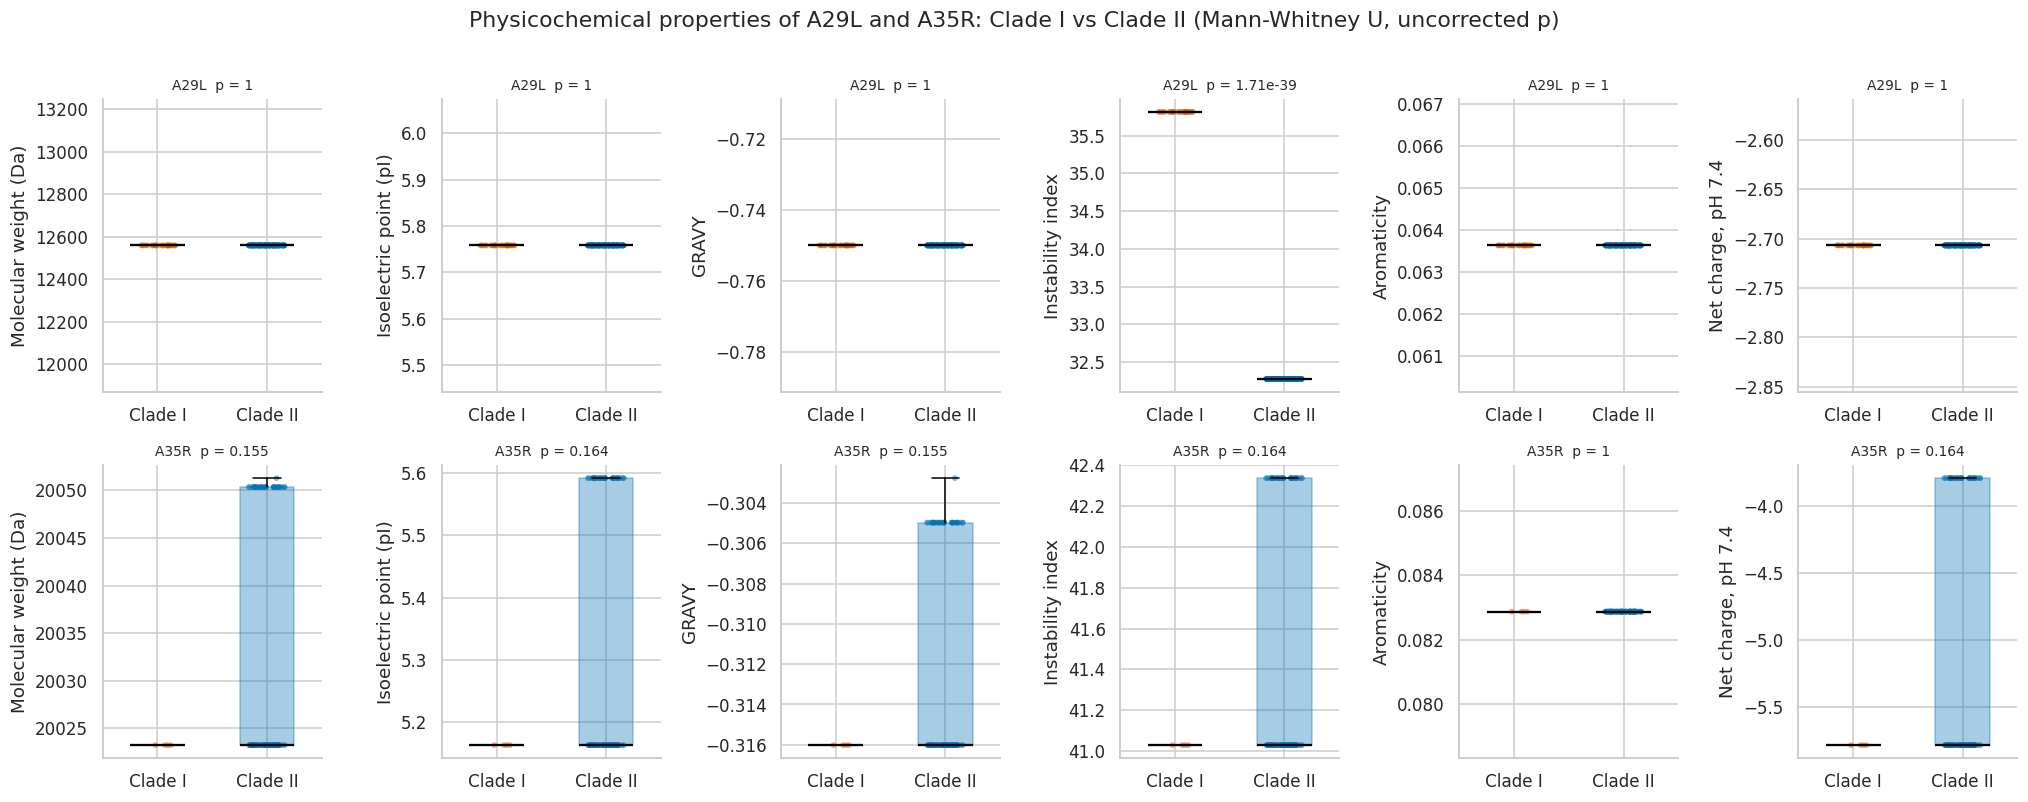

In [ ]:
# ----------------------- Boxplots + stripplots -----------------------
def box_strip(ax, data, prop, title_p=None):
    groups = [data[data.Clade == c][prop].dropna().values for c in CLADES]
    bp = ax.boxplot([g if len(g) else [np.nan] for g in groups], positions=[0, 1], widths=0.5, patch_artist=True, showfliers=False)
    rng = np.random.default_rng(42)
    for i, c in enumerate(CLADES):
        bp["boxes"][i].set(facecolor=CLADE_COLORS[c], alpha=0.35, edgecolor=CLADE_COLORS[c])
        bp["medians"][i].set(color="black", lw=1.5)
        if len(groups[i]) == 0:
            ax.text(i, 0.5, f"No {c}\nrecords in\ncurrent batch", transform=ax.get_xaxis_transform(), ha="center",
                    va="center", fontsize=8, color="#777777", style="italic",
                    bbox=dict(boxstyle="round", fc="#F4F4F4", ec="#CCCCCC"))
        if len(groups[i]):
            ax.scatter(i + rng.uniform(-0.17, 0.17, len(groups[i])), groups[i], s=14, alpha=0.5,
                       color=CLADE_COLORS[c], edgecolor="none")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Clade I", "Clade II"])
    ax.set_ylabel(PROP_LABEL[prop]); ax.set_title(title_p or "", fontsize=9)


fig, axes = plt.subplots(len(PROTEINS), len(PROPS), figsize=(3.1 * len(PROPS), 3.6 * len(PROTEINS)), squeeze=False)
seq_lvl = MWU[MWU.Level == "Sequence-level"].set_index(["Protein", "Property"])
for i, prot in enumerate(PROTEINS):
    for j, prop in enumerate(PROPS):
        d = df_feat_cls[df_feat_cls.Protein == prot]
        try:
            pv = seq_lvl.loc[(prot, prop), "p_value"]
            ttl = f"{prot}  p = {pv:.3g}" if pd.notna(pv) else f"{prot}  (test n/a)"
        except KeyError:
            ttl = prot
        box_strip(axes[i, j], d, prop, ttl)
fig.suptitle("Physicochemical properties of A29L and A35R: Clade I vs Clade II (Mann-Whitney U, uncorrected p)", y=1.01)
fig.tight_layout()
savefig(fig, "fig4_physicochemical_boxplots.png")
plt.show()

### Stage 5 (c): Pairwise Distance Matrix & Hierarchical Clustering (Phylogeny)  *(KDD phase 4)*

**Distance.** For two aligned haplotypes (star-MSA columns), the identity is
$\text{identity} = \dfrac{\#\text{matching residues}}{\#\text{columns where at least one sequence has a residue}}$ and the normalized distance is $d = 1 - \text{identity}$.

**Tree.** Average-linkage hierarchical clustering (**UPGMA**, `scipy.cluster.hierarchy.linkage(method="average")`) on the representative haplotypes. Leaves are colour-coded by clade. At most `MAX_LEAVES` of the most frequent haplotypes per protein are shown to keep the tree legible.

> **Why hierarchical clustering rather than K-means?**
> * Evolutionary relationships are **nested** (a tree), not a flat partition. Hierarchical clustering returns a dendrogram with branch heights equal to dissimilarity. K-means returns only $k$ unrelated groups.
> * K-means needs **vectors in Euclidean space**, since it averages them into centroids, and the number of clusters $k$ in advance. Protein sequences give a **distance matrix** (a mean of sequences is not a sequence), and the number of lineages is unknown.
> * K-means is stochastic (random initialisation) and tends to produce spherical clusters of similar size, which is unsuitable for lineages that differ in size and divergence. Hierarchical clustering is deterministic and reproducible.
> * UPGMA assumes a roughly constant substitution rate (a molecular clock), which is reasonable for closely related viral orthologs, and is only a *distance-based approximation*. Publication-grade phylogenies need maximum-likelihood or Bayesian inference (e.g. IQ-TREE, BEAST) on nucleotide or codon alignments.

/usr/local/lib/python3.13/dist-packages/scipy/cluster/hierarchy.py:1715: RuntimeWarning: invalid value encountered in scalar divide
  c = xp.sum(numerator) / xp.sqrt(xp.sum(denomA) * xp.sum(denomB))


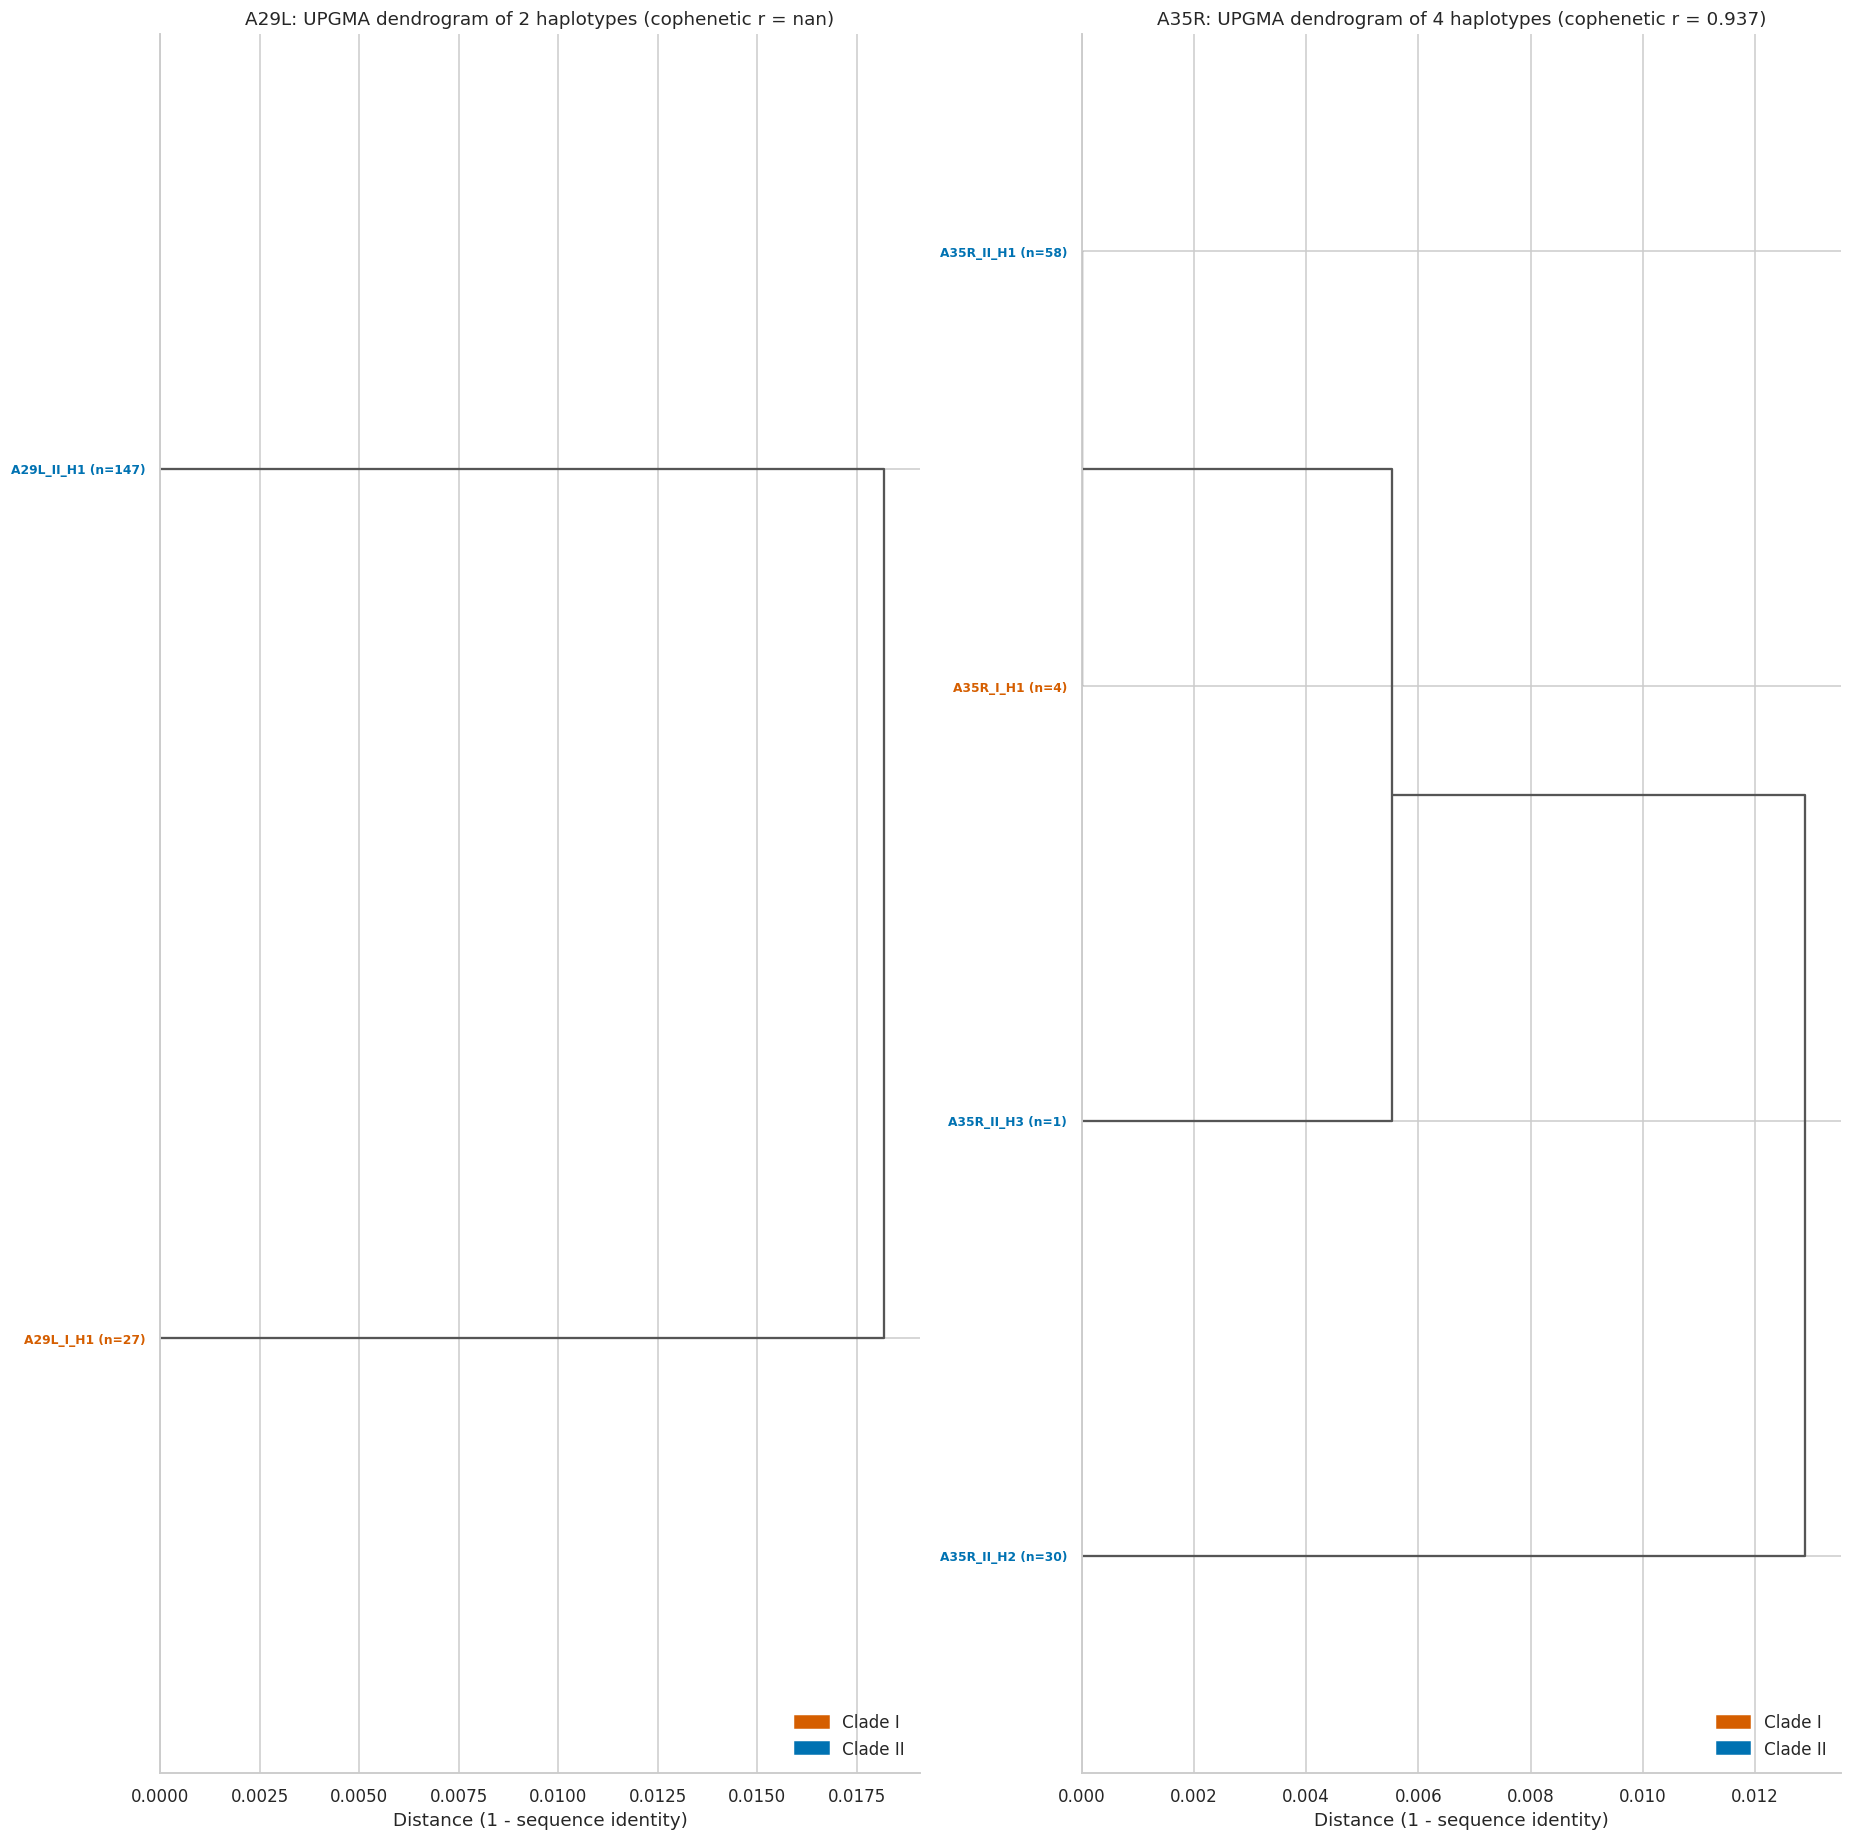


A29L: cut into 2 clusters vs known clade (weighted by haplotype frequency)


Clade,Clade I,Clade II
Cluster,,
1,27,0
2,0,147


   cluster purity with respect to clade: 100.0%

A35R: cut into 2 clusters vs known clade (weighted by haplotype frequency)


Clade,Clade I,Clade II
Cluster,,
1,4,59
2,0,30


   cluster purity with respect to clade: 95.7%
   mean distance between clades = 0.0055  vs  within clades = 0.0110


In [ ]:
# ----------------------- Distance matrices & dendrograms -----------------------
MAX_LEAVES = 60


def identity_distance_matrix(M):
    n = M.shape[0]
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            a, b = M[i], M[j]
            union = (a != "-") | (b != "-")
            match = (a == b) & (a != "-")
            D[i, j] = D[j, i] = 1.0 - match.sum() / max(int(union.sum()), 1)
    return D


TREES = {}
fig, axes = plt.subplots(1, len(ALN), figsize=(8.5 * len(ALN), 0.24 * MAX_LEAVES + 2.5), squeeze=False)
for ax, (prot, a) in zip(axes[0], ALN.items()):
    haps = a["haps"]
    sel = haps.sort_values("Freq", ascending=False).head(MAX_LEAVES).index.values
    sel = np.sort(sel)
    sub = haps.loc[sel].reset_index(drop=True)
    M = a["M"][sel]
    if len(sub) < 2:
        ax.text(0.5, 0.5, f"{prot}: fewer than 2 haplotypes -\nno tree can be built", ha="center", va="center")
        ax.axis("off")
        continue
    D = identity_distance_matrix(M)
    Z = hierarchy.linkage(squareform(D, checks=False), method="average")          # UPGMA
    coph, _ = hierarchy.cophenet(Z, squareform(D, checks=False))
    labels = [f"{h} (n={f})" for h, f in zip(sub.Haplotype, sub.Freq)]
    dn = hierarchy.dendrogram(Z, labels=labels, orientation="right", ax=ax, leaf_font_size=8,
                              color_threshold=0, above_threshold_color="#555555")
    cl_of = dict(zip(labels, sub.Clade))
    for t in ax.get_ymajorticklabels():
        t.set_color(CLADE_COLORS[cl_of[t.get_text()]])
        t.set_fontweight("bold")
    ax.set(title=f"{prot}: UPGMA dendrogram of {len(sub)} haplotypes (cophenetic r = {coph:.3f})",
           xlabel="Distance (1 - sequence identity)")
    ax.legend(handles=[Patch(color=CLADE_COLORS[c], label=c) for c in CLADES], loc="lower right", frameon=False)
    TREES[prot] = {"D": D, "Z": Z, "sub": sub, "coph": coph}
fig.tight_layout()
savefig(fig, "fig5_dendrograms.png")
plt.show()

# Do the two clades separate when the tree is cut into two clusters?
for prot, t in TREES.items():
    cl = hierarchy.fcluster(t["Z"], 2, criterion="maxclust")
    print(f"\n{prot}: cut into 2 clusters vs known clade (weighted by haplotype frequency)")
    tab = pd.crosstab(pd.Series(cl, name="Cluster"), pd.Series(t["sub"].Clade.values, name="Clade"),
                      values=t["sub"].Freq.values, aggfunc="sum").fillna(0).astype(int)
    display(tab)
    purity = tab.max(axis=1).sum() / tab.values.sum()
    print(f"   cluster purity with respect to clade: {purity:.1%}")
    inter = [t["D"][i, j] for i in range(len(t["sub"])) for j in range(i + 1, len(t["sub"]))
             if t["sub"].Clade[i] != t["sub"].Clade[j]]
    intra = [t["D"][i, j] for i in range(len(t["sub"])) for j in range(i + 1, len(t["sub"]))
             if t["sub"].Clade[i] == t["sub"].Clade[j]]
    if inter and intra:
        print(f"   mean distance between clades = {np.mean(inter):.4f}  vs  within clades = {np.mean(intra):.4f}")

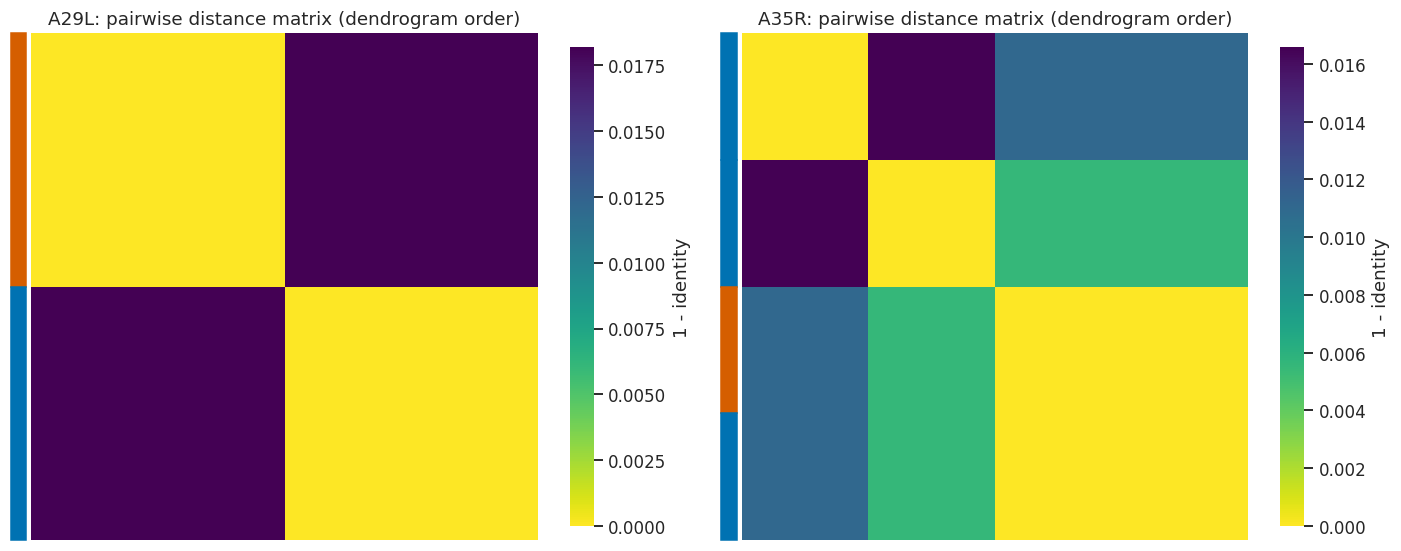

In [ ]:
# ----------------------- Distance heatmaps (supporting view) -----------------------
if TREES:
    fig, axes = plt.subplots(1, len(TREES), figsize=(6.5 * len(TREES), 5.8), squeeze=False)
    for ax, (prot, t) in zip(axes[0], TREES.items()):
        order = hierarchy.leaves_list(t["Z"])
        Dm = t["D"][np.ix_(order, order)]
        sns.heatmap(Dm, ax=ax, cmap="viridis_r", square=True, cbar_kws={"label": "1 - identity", "shrink": 0.8},
                    xticklabels=False, yticklabels=False)
        # clade colour strip along the left edge
        for k, idx in enumerate(order):
            ax.add_patch(plt.Rectangle((-0.04 * len(order), k), 0.03 * len(order), 1, clip_on=False,
                                       color=CLADE_COLORS[t["sub"].Clade[idx]]))
        ax.set_title(f"{prot}: pairwise distance matrix (dendrogram order)")
    fig.tight_layout()
    savefig(fig, "fig6_distance_heatmaps.png")
    plt.show()

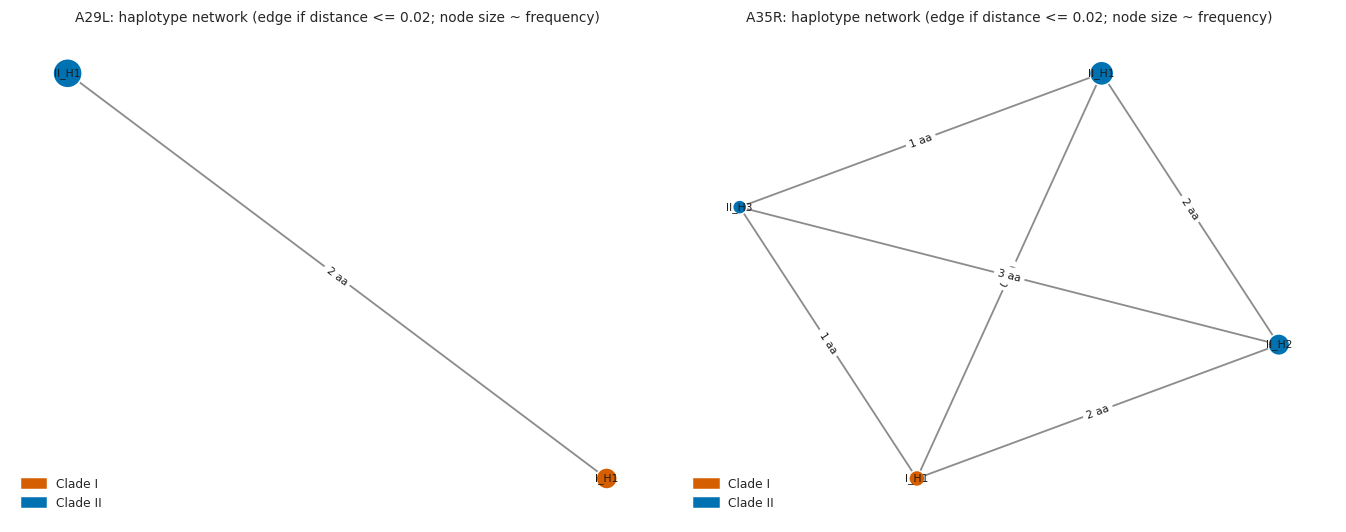

,Protein,Haplotypes,Edges (d<=0.02),Connected components,Cross-clade edges,Density
0,A29L,2,1,1,1,1.0
1,A35R,4,6,1,3,1.0


A29L: 1 of 1 edges link Clade I to Clade II haplotypes. Haplotypes from different clades sit within 2% of each other (clades are close, not isolated).
A35R: 3 of 6 edges link Clade I to Clade II haplotypes. Haplotypes from different clades sit within 2% of each other (clades are close, not isolated).


In [ ]:
# ----------------------- Stage 5: sequence-similarity (Hamming) network of haplotypes -----------------------
NET_D = 0.02                                   # connect haplotypes whose distance (1 - identity) is <= 2%


def hap_dist(a, b):
    if len(a) == len(b):
        return sum(x != y for x, y in zip(a, b)) / len(a)          # Hamming (equal length)
    return 1 - pct_identity(a, b)                                 # alignment-based otherwise


fig, axes = plt.subplots(1, len(PROTEINS), figsize=(6.2 * len(PROTEINS), 5), squeeze=False)
net_rows = []
for ax, prot in zip(axes[0], PROTEINS):
    h = HAP[HAP.Protein == prot].nlargest(120, "Freq").reset_index(drop=True)
    if len(h) < 2:
        ax.text(0.5, 0.5, f"{prot}: fewer than 2 haplotypes,\nno network to draw", ha="center", va="center"); ax.axis("off"); continue
    G = nx.Graph()
    for _, r in h.iterrows():
        G.add_node(r.Haplotype, clade=r.Clade, freq=r.Freq)
    for i in range(len(h)):
        for j in range(i + 1, len(h)):
            d = hap_dist(h.Sequence[i], h.Sequence[j])
            if d <= NET_D:
                G.add_edge(h.Haplotype[i], h.Haplotype[j], d=d, mm=round(d * len(h.Sequence[i])))
    pos = nx.spring_layout(G, seed=42, k=1.2)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.5, width=1.2)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[60 + 25 * np.sqrt(G.nodes[n]["freq"]) for n in G],
                           node_color=[CLADE_COLORS[G.nodes[n]["clade"]] for n in G], edgecolors="white")
    if G.number_of_nodes() <= 20:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, labels={n: n.split("_", 1)[1] for n in G})
        nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(u, v): f"{e['mm']} aa" for u, v, e in G.edges(data=True)}, font_size=7)
    cross = sum(G.nodes[u]["clade"] != G.nodes[v]["clade"] for u, v in G.edges)
    net_rows.append({"Protein": prot, "Haplotypes": G.number_of_nodes(), "Edges (d<=0.02)": G.number_of_edges(),
                     "Connected components": nx.number_connected_components(G), "Cross-clade edges": cross,
                     "Density": round(nx.density(G), 3)})
    ax.set_title(f"{prot}: haplotype network (edge if distance <= {NET_D}; node size ~ frequency)", fontsize=9)
    ax.legend(handles=[Patch(color=CLADE_COLORS[c], label=c) for c in CLADES], frameon=False, fontsize=8, loc="lower left")
    ax.axis("off")
fig.tight_layout(); savefig(fig, "fig_haplotype_network.png"); plt.show()
NETWORK = pd.DataFrame(net_rows); display(NETWORK)
for _, r in NETWORK.iterrows():
    print(f"{r.Protein}: {r['Cross-clade edges']} of {r['Edges (d<=0.02)']} edges link Clade I to Clade II haplotypes. "
          + ("Haplotypes from different clades sit within 2% of each other (clades are close, not isolated)."
             if r['Cross-clade edges'] > 0 else "No clade pair is within 2%: the clades form separate groups."))


In [ ]:
# ----------------------- Stage 5 checkpoint (fail fast) -----------------------
assert len(ALN) > 0, "No alignment was built (no clade-classified haplotypes)."
for _p, _a in ALN.items():
    assert _a["H_all"].min() >= 0 and _a["H_all"].max() <= np.log2(20) + 1e-9, f"{_p}: entropy outside [0, log2(20)]."
    assert _a["M"].shape[1] == len(_a["ref_seq"]), f"{_p}: alignment width differs from the reference length."
    assert _a["mut"].Position.between(1, len(_a["ref_seq"])).all(), f"{_p}: mutation position outside the sequence."
assert isinstance(MWU, pd.DataFrame), "Mann-Whitney table was not created."
if "p_value" in MWU:
    assert MWU.p_value.dropna().between(0, 1).all(), "p-values outside [0, 1]."
stage_ok(5, 5)


✔ Stage 5 checkpoint passed (5 checks).


<a id="stage6"></a>
## Stage 6: Biological Interpretation  *(KDD phase 5: Interpretation & Evaluation)*

**Method.** Statistics are linked back to biology in three steps: (i) the headline numbers of this run are printed; (ii) clade-distinguishing positions are mapped onto the **Kyte-Doolittle hydropathy profile** (window 9; windows of 19 residues above 1.6 are the classical signature of a membrane-spanning segment) to see whether they fall in hydrophobic, membrane-associated or charged, exposed regions; (iii) the substitution classes (conservative vs non-conservative, charge change) are reasoned against the known function of each protein. This is a **sequence-based inference**, not experimental evidence: it identifies candidates for structural or epitope follow-up.

In [ ]:
# ----------------------- Auto-generated findings summary -----------------------
print("=" * 78)
print("HEADLINE FINDINGS FROM THIS RUN")
print("=" * 78)
print(f"Sequences after QC: {len(df)} (clade-classified: {len(df_cls)}; Unclassified: {len(df) - len(df_cls)})")
for prot in PROTEINS:
    if prot not in ALN:
        print(f"\n{prot}: no clade-classified data."); continue
    a, m = ALN[prot], ALN[prot]["mut"]
    n_i = int(((df_cls.Protein == prot) & (df_cls.Clade == "Clade I")).sum())
    n_ii = int(((df_cls.Protein == prot) & (df_cls.Clade == "Clade II")).sum())
    print(f"\n{prot}: {n_i} Clade I / {n_ii} Clade II sequences, {len(a['haps'])} haplotypes, length {a['M'].shape[1]} aa")
    if len(m):
        cd = m[m.Category == "Clade-defining (fixed)"]
        cb = m[m.Category == "Clade-biased (majority differs)"]
        print(f"  variable positions: {len(m)} | clade-defining: {len(cd)} | clade-biased: {len(cb)} | "
              f"intra-clade polymorphic: {int((m.Category == 'Intra-clade polymorphism').sum())}")
        if len(cd):
            print("  clade-defining substitutions (Clade I -> Clade II): " + ", ".join(
                f"{r.Substitution[0]}{r.Position}{r.Substitution[-1]} [{r.Substitution_type}]" for _, r in cd.iterrows()))
            print(f"  of which non-conservative: {int((cd.Substitution_type == 'Non-conservative').sum())}; "
                  f"charge-altering: {int((cd.Delta_charge.fillna(0) != 0).sum())}")
    cons = 100 * (a["H_all"] == 0).mean()
    print(f"  fully conserved columns (entropy = 0): {cons:.1f}% of positions")
    if (prot, "Clade I") in REFS and (prot, "Clade II") in REFS:
        (_, sI), (_, sII) = REFS[(prot, "Clade I")], REFS[(prot, "Clade II")]
        ga = g_al.align(sI, sII)[0]; mm, _, cc = aln_stats(ga, sI, sII)
        print(f"  reference-vs-reference global identity: {100 * mm / cc:.1f}%")
    ps = MWU[(MWU.Protein == prot) & (MWU.Level == "Haplotype-level") & MWU.p_value.notna()] if "p_value" in MWU else []
    if len(ps):
        best = ps.sort_values("p_value").iloc[0]
        print(f"  lowest haplotype-level p-value: {best.Property} p = {best.p_value:.3g} "
              f"(Bonferroni {best.p_Bonferroni:.3g})")
    if prot in TREES:
        print(f"  UPGMA cophenetic correlation: {TREES[prot]['coph']:.3f}")

HEADLINE FINDINGS FROM THIS RUN
Sequences after QC: 316 (clade-classified: 267; Unclassified: 49)

A29L: 27 Clade I / 147 Clade II sequences, 2 haplotypes, length 110 aa
  variable positions: 2 | clade-defining: 2 | clade-biased: 0 | intra-clade polymorphic: 0
  clade-defining substitutions (Clade I -> Clade II): H74R [Non-conservative], R107H [Non-conservative]
  of which non-conservative: 2; charge-altering: 2
  fully conserved columns (entropy = 0): 98.2% of positions
  reference-vs-reference global identity: 98.2%
  UPGMA cophenetic correlation: nan

A35R: 4 Clade I / 89 Clade II sequences, 4 haplotypes, length 181 aa
  variable positions: 3 | clade-defining: 0 | clade-biased: 0 | intra-clade polymorphic: 3
  fully conserved columns (entropy = 0): 98.3% of positions
  reference-vs-reference global identity: 100.0%
  UPGMA cophenetic correlation: 0.937


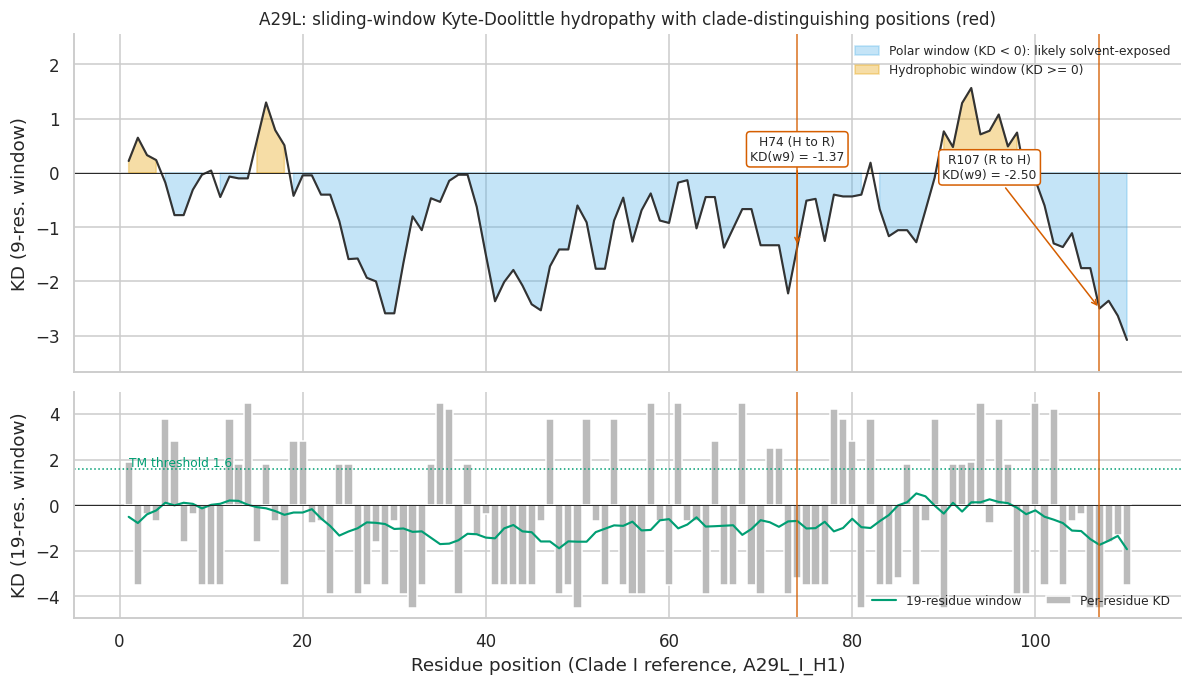

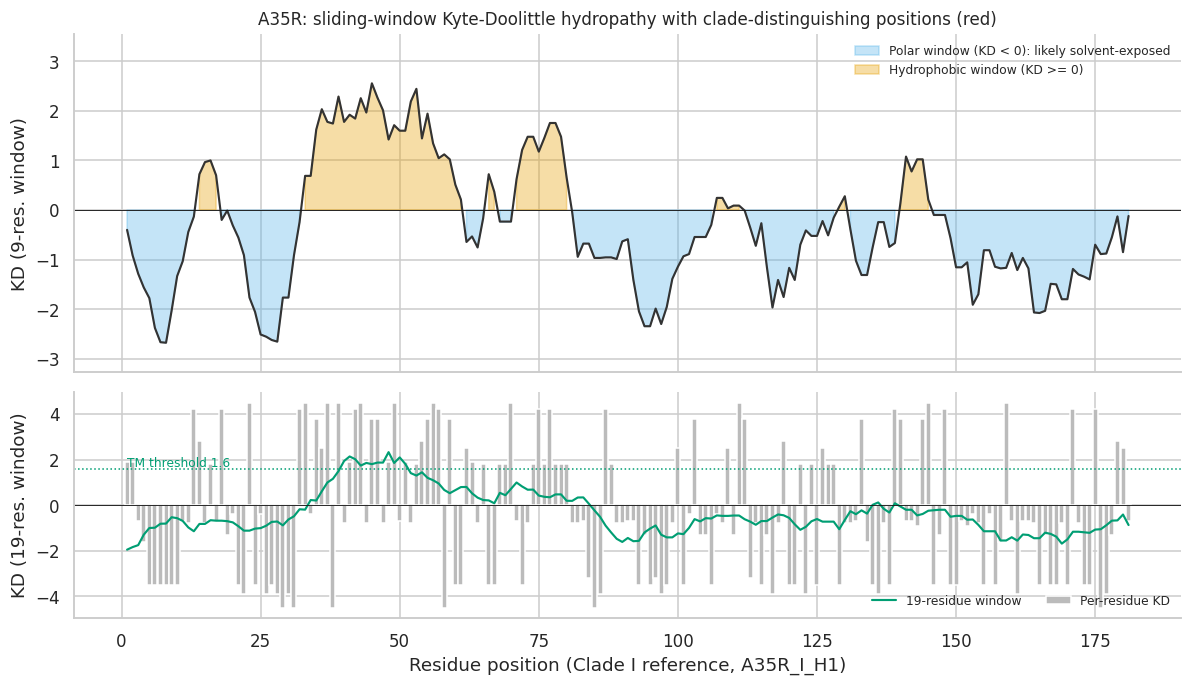

,Protein,Position,Ref_residue,Substitution,Class,BLOSUM62,Delta_charge,KD_window9,KD_window19,Region
0,A29L,74,H,H->R,Non-conservative,0.0,1,-1.37,-0.69,"polar, solvent-exposed"
1,A29L,107,R,R->H,Non-conservative,0.0,-1,-2.50,-1.74,"polar, solvent-exposed"


A29L: 2 clade-distinguishing position(s); 2 in polar windows (KD < 0), 0 in hydrophobic/TM windows. All sit in polar, probably solvent-exposed regions, so a disruption of a hydrophobic core is unlikely.

Heparin-binding check (A29L, residues 21-30, literature-derived, verify): 0 of 2 clade-distinguishing positions fall inside the region (positions 74, 107 lie outside it), so they are not inside the assumed N-terminal stretch (confirm the coordinates in the cited paper).


In [ ]:
# ----------------------- Stage 6: dual-panel Kyte-Doolittle hydropathy with annotated positions -----------------------
def kd_edge(seq, w):
    """Mean Kyte-Doolittle hydropathy in a centred window of w residues; windows are truncated at the termini,
    so every position (including the last few) gets a value."""
    v = np.array([KYTE_DOOLITTLE.get(a, 0.0) for a in seq]); h = w // 2
    return np.array([v[max(0, i - h):i + h + 1].mean() for i in range(len(seq))])


TM_THRESHOLD, POLAR_CUT = 1.6, 0.0
bio_rows = []
for prot, a in ALN.items():
    rc = a["ref_clade"]; seq = a["ref_seq"]; x = np.arange(1, len(seq) + 1)
    k9, k19 = kd_edge(seq, 9), kd_edge(seq, 19)
    m = a["mut"]
    sel = m[m.Category.isin(["Clade-defining (fixed)", "Clade-biased (majority differs)"])]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
    ax1.plot(x, k9, c="#333333", lw=1.4)
    ax1.fill_between(x, k9, POLAR_CUT, where=k9 < POLAR_CUT, color="#56B4E9", alpha=0.35, label="Polar window (KD < 0): likely solvent-exposed")
    ax1.fill_between(x, k9, POLAR_CUT, where=k9 >= POLAR_CUT, color="#E69F00", alpha=0.35, label="Hydrophobic window (KD >= 0)")
    ax1.axhline(0, c="k", lw=0.6)
    ax2.plot(x, k19, c="#009E73", lw=1.4, label="19-residue window")
    ax2.axhline(TM_THRESHOLD, c="#009E73", ls=":", lw=1); ax2.text(1, TM_THRESHOLD + 0.1, "TM threshold 1.6", ha="left", fontsize=8, color="#009E73")
    ax2.bar(x, [KYTE_DOOLITTLE.get(c, 0) for c in seq], color="#BBBBBB", width=0.9, label="Per-residue KD")
    ax2.axhline(0, c="k", lw=0.6)
    for n_, (_, r) in enumerate(sel.head(8).iterrows()):
        p = int(r.Position); v9 = k9[p - 1]; v19 = k19[p - 1]
        region = ("putative TM/hydrophobic" if v19 > TM_THRESHOLD else "hydrophobic" if v9 >= 0.5 else
                  "intermediate" if v9 >= POLAR_CUT else "polar, solvent-exposed")
        for ax in (ax1, ax2):
            ax.axvline(p, c="#D55E00", lw=1.1, alpha=0.8)
        ax1.annotate(f"{seq[p - 1]}{p} ({r.Substitution.replace('->', ' to ')})\nKD(w9) = {v9:.2f}", xy=(p, v9),
                     xytext=(p - (12 if p > 0.85 * len(seq) else 0), v9 + (1.6 if v9 < 0 else -1.6) + (0.8 if n_ % 2 else 0)), ha="center", fontsize=8,
                     arrowprops=dict(arrowstyle="->", color="#D55E00"), bbox=dict(boxstyle="round", fc="white", ec="#D55E00"))
        bio_rows.append({"Protein": prot, "Position": p, "Ref_residue": seq[p - 1], "Substitution": r.Substitution,
                         "Class": r.Substitution_type, "BLOSUM62": r.BLOSUM62, "Delta_charge": r.Delta_charge,
                         "KD_window9": round(float(v9), 2), "KD_window19": round(float(v19), 2), "Region": region})
    ax1.set_ylim(min(k9.min(), -1) - 0.6, max(k9.max(), 1) + 1.0)
    ax1.set_ylabel("KD (9-res. window)"); ax2.set_ylabel("KD (19-res. window)")
    ax2.set_xlabel(f"Residue position ({rc} reference, {a['ref_id']})")
    ax1.set_title(f"{prot}: sliding-window Kyte-Doolittle hydropathy with clade-distinguishing positions (red)", fontsize=11)
    ax1.legend(frameon=False, fontsize=8, loc="upper right"); ax2.legend(frameon=False, fontsize=8, loc="lower right", ncol=2)
    fig.tight_layout(); savefig(fig, f"fig_bio_hydropathy_{prot}.png"); plt.show()

BIO = pd.DataFrame(bio_rows)
if len(BIO):
    display(BIO); BIO.to_csv("mpox_bio_interpretation.csv", index=False)
    for prot, g in BIO.groupby("Protein"):
        npolar = int((g.Region == "polar, solvent-exposed").sum())
        print(f"{prot}: {len(g)} clade-distinguishing position(s); {npolar} in polar windows (KD < 0), "
              f"{int((g.Region.str.contains('hydrophobic')).sum())} in hydrophobic/TM windows. "
              + ("All sit in polar, probably solvent-exposed regions, so a disruption of a hydrophobic core is unlikely."
                 if npolar == len(g) else "Some sit in hydrophobic windows and deserve structural follow-up."))
else:
    print("No clade-defining or clade-biased positions in this dataset, so there is nothing to map. "
          "This is itself a result: the two clades are identical at the sampled positions.")

# ---- literature-derived hypothesis: is a clade-defining residue inside the reported heparin-binding region? ----
HEPARIN_REGION = {"A29L": (21, 30)}     # N-terminal heparan-sulfate-binding stretch reported for vaccinia A27 (VERIFY in PMC9629035)
for prot, (lo, hi) in HEPARIN_REGION.items():
    g = BIO[BIO.Protein == prot] if len(BIO) else BIO
    if len(g):
        inside = g[g.Position.between(lo, hi)]
        print(f"\nHeparin-binding check ({prot}, residues {lo}-{hi}, literature-derived, verify): "
              f"{len(inside)} of {len(g)} clade-distinguishing positions fall inside the region "
              + (f"({', '.join(map(str, inside.Position))})." if len(inside) else
                 "(positions " + ", ".join(map(str, g.Position)) + " lie outside it), so they are not inside the assumed N-terminal stretch (confirm the coordinates in the cited paper)."))


### Literature comparison (links the result back to the question)

* **Heparin binding.** A29 binds heparin and other glycosaminoglycans, and published work reports that MPXV A29 keeps heparin binding despite a few amino-acid differences from other orthopoxvirus homologs ([PMC9629035](https://pmc.ncbi.nlm.nih.gov/articles/PMC9629035), [PMC9503980](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9503980/)). Our check above asks whether the clade-defining residues fall in the reported binding stretch. If they do not, the data give **no sequence-level reason to expect a clade difference in attachment**, but this is a hypothesis, not proof.
* **Vaccine relevance.** A29L is used in multi-antigen mouse vaccines and A29L mAbs neutralise ([PMC10286687](https://pmc.ncbi.nlm.nih.gov/articles/PMC10286687), [PMC10331816](https://pmc.ncbi.nlm.nih.gov/articles/PMC10331816)). Two clade-specific residues on the surface mean that clade-specific epitope mapping (for example in IEDB) is worth doing before claiming one antigen covers both clades.
* **Limit of this evidence.** Hydropathy and conservation are sequence-based proxies. They cannot show binding, folding or immune escape; only structures (PDB, see the provenance table in Stage 3), binding assays and neutralisation data can.

### 6.1 Reading the results: cross-clade conservation

* **Conservation.** A29L and A35R are structural, essential virion proteins, so low per-position entropy and high Clade I vs Clade II identity are expected. The dendrogram and the cluster-purity table show whether the few substitutions are enough to separate the clades. Clean separation with a handful of clade-defining residues means the clades are distinguishable, but only at a few sites.
* **Mutation type.** Positions listed as *Clade-defining (fixed)* are the strongest candidates for clade-specific markers. Mostly **conservative** substitutions (BLOSUM62 > 0, small ΔKD, Δcharge = 0) suggest functional constraint is preserved. **Non-conservative or charge-altering** changes, especially in regions involved in heparan sulfate binding (A29L) or in the coiled-coil / glycosylated ectodomain (A35R), deserve closer structural and functional study.
* **Physicochemistry.** If the Mann-Whitney tests are not significant at the haplotype level after correction, surface charge (pI, net charge) and hydrophobicity (GRAVY) are effectively conserved across clades. A difference that is significant only at the *sequence* level, not the haplotype level, mostly reflects **sampling bias** (many identical outbreak sequences) and not a real biochemical shift.

### 6.2 Implications for pan-Mpox vaccines and diagnostics

* **Vaccines.** Orthopoxvirus A27/A29 and A33/A35 antigens are components of subunit and mRNA vaccine designs. High cross-clade conservation, with no clade-defining changes at known epitopes, supports a single antigen sequence protecting against both clades. Any clade-defining residue should be checked against mapped neutralizing epitopes (for example in IEDB) and, where relevant, against glycosylation sites before choosing a vaccine immunogen.
* **Diagnostics.** Conserved, low-entropy windows suit **pan-Mpox** assays (antibody or antigen tests, PCR targets at the matching gene region). Clade-defining positions can be used as **clade-discriminating** markers. Assay design should always be re-checked at nucleotide level, because synonymous variation is invisible in protein alignments.
* **Antigenic stability.** Instability index and aromaticity serve as coarse proxies for in-vitro stability of recombinant antigens. Large clade differences would argue for testing both variants in expression and stability studies.

### 6.3 Limitations

1. **Clade assignment is metadata-driven.** Protein records often lack country, date and isolate. Cameroon hosts both clades. Some records stay Unclassified, and rule-based calls can be wrong. Verify important calls against the linked nucleotide record or Nextstrain / NCBI Virus clade annotations.
2. **Sampling bias.** The 2022+ Clade IIb outbreak is heavily over-sequenced relative to Clade I. Haplotype-level statistics reduce but do not remove this.
3. **Annotation noise.** Records come from keyword searches and length filters, so a few unrelated proteins or partial or mis-annotated records may slip through (see the `Annot_Match` flag).
4. **Star alignment.** The multiple alignment is a reference-based approximation. Insertions relative to the reference are discarded, and numbering follows the Clade I reference. For indel-rich data, use MAFFT or MUSCLE.
5. **UPGMA.** The tree is distance-based and assumes a clock. It has no branch support values. Use a maximum-likelihood tree (IQ-TREE) with bootstrap support for any phylogenetic claim.
6. **Protein level only.** Synonymous changes, regulatory regions, structural context and experimental epitope data are out of scope.

### 6.4 Reproducibility: freezing the dataset

NCBI is a **living database**. New records are added, and annotations and versions change, so the same query can return different data next week. The Entrez API also rate-limits, throttles and times out. This notebook handles both problems:

* **Local-first ingestion.** The manually exported `mpox_a29l.gb` and `mpox_a35r.gb` are a fixed, citable snapshot that parses in seconds without network calls. Keep them (and the cache) under version control with the notebook.
* **Cache.** `mpox_raw_gb_cache.gb` freezes any API download, so a rerun does not hit NCBI again.
* **Timeouts and retries.** `socket.setdefaulttimeout(15)`, 50-ID chunks, 0.4 s pacing and 3 retries mean a stalled stream can never hang the kernel.
* **Manifest.** The next cell records input checksums, versions and counts.

<a id="stage7"></a>
## Stage 7: Machine Learning  *(KDD phase 4, supervised and unsupervised)*

**Question.** Can clade (I vs II) be predicted from the sequence-derived features (6 physicochemical descriptors plus 20 amino-acid fractions)? The honest answer depends on the evaluation design, so three are shown:

1. **Baselines.** Majority-class and stratified-random dummy classifiers. A model is only interesting if it beats these.
2. **Naive stratified K-fold (leaky).** Identical sequences appear in both training and test folds, so scores are inflated. Shown only to demonstrate the leakage.
3. **Leave-one-haplotype-out (grouped, leak-free).** All copies of a haplotype are held out together. This tests generalisation to a **sequence the model has never seen**. If the held-out haplotype is the only one of its clade, the clade is absent from training and the fold is **not estimable**, which is reported as such and not hidden.

**Metrics.** Balanced accuracy and Matthews correlation coefficient (MCC), which stay honest under class imbalance; accuracy alone would be misleading because Clade II dominates the outbreak data.

**Unsupervised check.** K-means (k=2, needs vectors) and hierarchical clustering (k=2) on the features, scored against clade by the Adjusted Rand Index (ARI; 0 = chance, 1 = perfect).

In [ ]:
# ----------------------- Stage 7: ML with baselines and leakage-free evaluation -----------------------
import warnings; warnings.filterwarnings("ignore")
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef, adjusted_rand_score
from sklearn.cluster import KMeans, AgglomerativeClustering
SEED = 42
FEATS = PROPS + AA
MODELS = {
    "Baseline: majority": lambda: DummyClassifier(strategy="most_frequent"),
    "Baseline: stratified random": lambda: DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest": lambda: RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED),
}

def score(y, p):
    return balanced_accuracy_score(y, p), (matthews_corrcoef(y, p) if len(set(y)) > 1 else np.nan)

ml_rows, ml_notes = [], []
hapmap = df_cls[["Accession", "Haplotype"]].drop_duplicates("Accession")
for prot in PROTEINS:
    g = df_feat_cls[df_feat_cls.Protein == prot].merge(hapmap, on="Accession", how="left")
    ac = pd.DataFrame({"Sequence": g.Sequence.unique()}); ac = pd.concat([ac, ac.Sequence.apply(aa_comp)], axis=1)
    g = g.merge(ac, on="Sequence", how="left").dropna(subset=FEATS + ["Haplotype"])
    y = (g.Clade == "Clade II").astype(int).values
    cnt = pd.Series(y).value_counts().to_dict()
    nh = g.groupby("Clade").Haplotype.nunique().to_dict()
    if len(cnt) < 2:
        msg = f"{prot}: only one clade present ({g.Clade.unique().tolist()}), so clade prediction is NOT POSSIBLE. Reported as such."
        print(msg); ml_notes.append(msg); continue
    print(f"\n{prot}: n={len(g)} sequences, class counts (1=Clade II): {cnt}; distinct haplotypes per clade: {nh}")
    X = g[FEATS].values; grp = g.Haplotype.values
    for name, mk in MODELS.items():
        # (2) naive stratified CV  -> leaky
        k = min(5, min(cnt.values()))
        if k >= 2:
            pred = np.empty_like(y)
            for tr, te in StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, y):
                pred[te] = mk().fit(X[tr], y[tr]).predict(X[te])
            ba, mcc = score(y, pred)
            ml_rows.append({"Protein": prot, "Model": name, "Evaluation": "Naive stratified CV (LEAKY)",
                            "Balanced_acc": ba, "MCC": mcc, "Folds_valid": k})
        # (3) leave-one-haplotype-out
        yt, yp, valid, skipped = [], [], 0, 0
        for tr, te in LeaveOneGroupOut().split(X, y, grp):
            if len(set(y[tr])) < 2:
                skipped += 1; continue
            yp.extend(mk().fit(X[tr], y[tr]).predict(X[te])); yt.extend(y[te]); valid += 1
        if valid and len(set(yt)) > 1:
            ba, mcc = score(np.array(yt), np.array(yp))
        elif valid:
            ba, mcc = np.nan, np.nan
        else:
            ba, mcc = np.nan, np.nan
        ml_rows.append({"Protein": prot, "Model": name, "Evaluation": "Leave-one-haplotype-out (leak-free)",
                        "Balanced_acc": ba, "MCC": mcc, "Folds_valid": valid, "Folds_not_estimable": skipped})
    # unsupervised
    Xs = StandardScaler().fit_transform(X[:, X.std(axis=0) > 0]) if (X.std(axis=0) > 0).any() else None
    if Xs is not None and len(np.unique(Xs, axis=0)) >= 2:
        km = KMeans(2, n_init=10, random_state=SEED).fit_predict(Xs)
        _u = list(dict.fromkeys(g.Sequence))                      # UPGMA on the 1 - identity distance matrix (like Stage 5c)
        _D = np.array([[0.0 if a == b else 1 - pct_identity(a, b) for b in _u] for a in _u])
        _lab = hierarchy.fcluster(hierarchy.linkage(squareform(_D, checks=False), "average"), 2, "maxclust")
        _m = dict(zip(_u, _lab)); hc = np.array([_m[s] for s in g.Sequence])
        ml_rows.append({"Protein": prot, "Model": "K-means (k=2)", "Evaluation": "Unsupervised ARI vs clade",
                        "Balanced_acc": np.nan, "MCC": np.nan, "ARI": adjusted_rand_score(y, km)})
        ml_rows.append({"Protein": prot, "Model": "UPGMA (k=2, 1-identity)", "Evaluation": "Unsupervised ARI vs clade",
                        "Balanced_acc": np.nan, "MCC": np.nan, "ARI": adjusted_rand_score(y, hc)})
    else:
        ml_notes.append(f"{prot}: features are constant across sequences, so clustering is undefined.")

ML = pd.DataFrame(ml_rows)
if len(ML):
    display(ML.round(3)); ML.to_csv("mpox_ml_results.csv", index=False)
    f = ML[ML.Evaluation.str.startswith("Naive")].pivot_table(index=["Protein", "Model"], values="Balanced_acc")
    f2 = ML[ML.Evaluation.str.startswith("Leave")].pivot_table(index=["Protein", "Model"], values="Balanced_acc", dropna=False)
    print("\nINTERPRETATION (generated from this run)")
    for prot in ML.Protein.unique():
        L = ML[(ML.Protein == prot) & ML.Evaluation.str.startswith("Leave")]
        N = ML[(ML.Protein == prot) & ML.Evaluation.str.startswith("Naive")]
        if L.Folds_valid.max() == 0 or L.Balanced_acc.isna().all():
            print(f"- {prot}: leave-one-haplotype-out is NOT ESTIMABLE (every held-out haplotype removes its clade from training). "
                  "Any high naive-CV score here reflects memorised identical sequences, not generalisation.")
        else:
            best = L.sort_values("Balanced_acc", ascending=False).iloc[0]
            base = L[L.Model.str.startswith("Baseline")].Balanced_acc.max()
            verdict = "beats" if best.Balanced_acc > base + 0.05 else "does not clearly beat"
            print(f"- {prot}: best leak-free model {best.Model} (balanced acc {best.Balanced_acc:.2f}) {verdict} the best baseline ({base:.2f}).")
        if len(N):
            print(f"  naive CV best balanced accuracy {N.Balanced_acc.max():.2f} (leaky; do not report as performance).")
for n in ml_notes: print("-", n)
if not len(ML): print("No ML evaluation was possible with this dataset.")



A29L: n=174 sequences, class counts (1=Clade II): {1: 147, 0: 27}; distinct haplotypes per clade: {'Clade I': 1, 'Clade II': 1}

A35R: n=93 sequences, class counts (1=Clade II): {1: 89, 0: 4}; distinct haplotypes per clade: {'Clade I': 1, 'Clade II': 3}


,Protein,Model,Evaluation,Balanced_acc,MCC,Folds_valid,Folds_not_estimable,ARI
0,A29L,Baseline: majority,Naive stratified CV (LEAKY),0.500,0.000,5.0,NaN,NaN
1,A29L,Baseline: majority,Leave-one-haplotype-out (leak-free),NaN,NaN,0.0,2.0,NaN
2,A29L,Baseline: stratified random,Naive stratified CV (LEAKY),0.528,0.059,5.0,NaN,NaN
3,A29L,Baseline: stratified random,Leave-one-haplotype-out (leak-free),NaN,NaN,0.0,2.0,NaN
4,A29L,Logistic regression,Naive stratified CV (LEAKY),1.000,1.000,5.0,NaN,NaN
5,A29L,Logistic regression,Leave-one-haplotype-out (leak-free),NaN,NaN,0.0,2.0,NaN
6,A29L,Random forest,Naive stratified CV (LEAKY),1.000,1.000,5.0,NaN,NaN
7,A29L,Random forest,Leave-one-haplotype-out (leak-free),NaN,NaN,0.0,2.0,NaN
8,A29L,K-means (k=2),Unsupervised ARI vs clade,NaN,NaN,NaN,NaN,1.000
9,A29L,"UPGMA (k=2, 1-identity)",Unsupervised ARI vs clade,NaN,NaN,NaN,NaN,1.000



INTERPRETATION (generated from this run)
- A29L: leave-one-haplotype-out is NOT ESTIMABLE (every held-out haplotype removes its clade from training). Any high naive-CV score here reflects memorised identical sequences, not generalisation.
  naive CV best balanced accuracy 1.00 (leaky; do not report as performance).
- A35R: leave-one-haplotype-out is NOT ESTIMABLE (every held-out haplotype removes its clade from training). Any high naive-CV score here reflects memorised identical sequences, not generalisation.
  naive CV best balanced accuracy 0.67 (leaky; do not report as performance).


**Reading Stage 7.** The decisive comparison is *leak-free versus naive*. With near-identical orthologs, most sequences in a clade are the same string, so a random split lets the model memorise it. When each clade has only one or two haplotypes, no honest generalisation test exists and the correct conclusion is that the question is **not estimable with these data**, not that the model works. Higher-resolution signals (whole-genome SNP data, many more clade-specific haplotypes) would be needed for a meaningful classifier. **Accuracy is deliberately not used as the headline metric.** Under leave-one-haplotype-out the majority baseline can score *below* 0.5, because a held-out haplotype of the minority clade is predicted as the majority clade; this is expected and is why the stratified-random baseline is also shown.

In [ ]:
# ----------------------- Stage 7 checkpoint (fail fast) -----------------------
assert isinstance(ML, pd.DataFrame), "The ML table was not created."
if len(ML):
    assert {"Model", "Evaluation"} <= set(ML.columns), "Unexpected ML table layout."
    assert not ML[ML.Evaluation.str.startswith("Naive")].Balanced_acc.dropna().gt(1).any(), "Balanced accuracy above 1."
stage_ok(7, 3)


✔ Stage 7 checkpoint passed (3 checks).


<a id="stage8"></a>
## Stage 8: Conclusions, Limitations, Future Work & Submission

### Conclusions
The generated block above states one conclusion per objective, with the numbers from your run. Copy those numbers into the report, and say plainly which claims are **supported**, which are **inconclusive**, and which are **not estimable**.

### Limitations
1. **Clade labels are inferred** from free text, country and year, not read from a curated field, so some mislabelling is possible.
2. **Sampling bias and duplication.** Outbreak data are dominated by identical sequences from a few countries and years. Sequence-level statistics are inflated; haplotype-level statistics have very small n.
3. **Few haplotypes per clade** (sometimes one) make haplotype-level tests, cophenetic correlation and leak-free ML trivial or not estimable.
4. **Protein-only view.** Synonymous and non-coding changes, and recombination, are invisible; UPGMA on identity is a distance approximation, not a phylogeny.
5. **Global descriptors** (pI, GRAVY, ...) are insensitive to single swaps; a swap pair such as H<->R at two positions can leave composition-based values unchanged.
6. **No structural or epitope data** were used; Stage 6 is hypothesis-generating.
7. **BLOSUM62 > 0 as "conservative"** means a score of 0 is labelled non-conservative; positions at the boundary should be judged individually.

### Grounded next steps
* **Verify the lookalike labels** in the QC audit against the RefSeq annotation (NC_063383): confirm which gene is A35R (OPG161), A36R (168 aa) and A37R (176 aa).
* **Structure check**: map clade-defining residues onto the PDB structures listed in the provenance table and use a coiled-coil/leucine-zipper predictor on A29L.
* **Epitope check**: look the same positions up in IEDB before claiming cross-clade vaccine coverage.

### Future steps
* Add nucleotide/whole-genome alignments and ML or Bayesian trees (IQ-TREE, BEAST); include clade Ia/Ib/IIa/IIb sub-lineages.
* Map clade-defining residues onto experimental structures and mapped epitopes (IEDB, PDB).
* Re-run with a date-stamped, larger retrieval and a prespecified holdout of whole lineages for ML.

### Submitting to GitHub (required deliverable)
1. Create a repository (e.g. `mpox-a29l-a35r-analysis`) and add: this notebook **with outputs saved**, a `README.md` (question, data source, how to run), `requirements.txt`, and the data files or a note on how to regenerate them.
2. In Colab: **File > Save a copy in GitHub**, or download the `.ipynb` and `git add . && git commit -m "Mpox A29L/A35R analysis" && git push`.
3. Check the notebook runs **Runtime > Restart and run all** with no errors before pushing, and that no personal data or keys are committed.
4. Paste the repository link in your submission.

In [ ]:
# ----------------------- Stage 8: conclusions per objective (generated from this run) -----------------------
print("=" * 78); print("CONCLUSIONS PER OBJECTIVE"); print("=" * 78)
print(f"O1 Dataset: {len(df)} QC-passed sequences from {len(RAW_RECORDS)} raw records; {len(df_cls)} clade-classified "
      f"({df_cls.Clade.value_counts().to_dict()}); {len(HAP)} haplotypes.")
for prot, a in ALN.items():
    m = a["mut"]
    nd = int((m.Category == "Clade-defining (fixed)").sum()) if len(m) else 0
    print(f"O2 {prot}: {100*(a['H_all']==0).mean():.1f}% of positions fully conserved; {nd} clade-defining substitution(s).")
if "p_value" in MWU:
    hl = MWU[(MWU.Level == "Haplotype-level") & MWU.p_value.notna()]
    sg = MWU[(MWU.Level == "Sequence-level") & (MWU.get("Significant (p<0.05)", False) == True)]
    print(f"O3 Physicochemistry: {len(sg)} sequence-level test(s) significant after Bonferroni; "
          f"{len(hl)} haplotype-level test(s) were estimable. Sequence-level significance driven by duplicated sequences is NOT biological evidence.")
else:
    print("O3 Physicochemistry: no estimable test (fewer than 2 observations per clade).")
if len(ML):
    print("O4 Prediction/clustering: see the leak-free versus naive table above; state 'not estimable' where reported.")
else:
    print("O4 Prediction/clustering: not estimable with this dataset.")


CONCLUSIONS PER OBJECTIVE
O1 Dataset: 316 QC-passed sequences from 476 raw records; 267 clade-classified ({'Clade II': 236, 'Clade I': 31}); 6 haplotypes.
O2 A29L: 98.2% of positions fully conserved; 2 clade-defining substitution(s).
O2 A35R: 98.3% of positions fully conserved; 0 clade-defining substitution(s).
O3 Physicochemistry: 1 sequence-level test(s) significant after Bonferroni; 0 haplotype-level test(s) were estimable. Sequence-level significance driven by duplicated sequences is NOT biological evidence.
O4 Prediction/clustering: see the leak-free versus naive table above; state 'not estimable' where reported.


In [ ]:
# ----------------------- Stage 8: exports, CONSOLIDATED_FINDINGS, reproducibility manifest -----------------------
from IPython.display import Markdown
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# ---- 1. export ----
df.drop(columns=["Description"]).to_csv("mpox_clean_dataset.csv", index=False)
HAP.to_csv("mpox_haplotypes.csv", index=False)
with open("mpox_haplotypes.fasta", "w") as fh:
    for _, r in HAP.iterrows():
        fh.write(f">{r.Haplotype}|{r.Protein}|{r.Clade}|n={r.Freq}\n{r.Sequence}\n")

# ---- 2. CONSOLIDATED_FINDINGS: objectives O1-O4 mapped to their quantitative answers ----
rows = []
ref_txt = "; ".join(f"{r.Protein}: reference {r.Reference_length} aa (expected {r.Expected_length}), {r['Dropped_%']}% dropped" for _, r in AUDIT.iterrows())
rows.append(["O1", "Curated, documented dataset",
             f"{len(RAW_RECORDS)} raw -> {len(df)} after QC -> {len(df_cls)} clade-classified ({df_cls.Clade.value_counts().to_dict()}); {len(HAP)} haplotypes. QC audit: {ref_txt}.",
             "Supported", "Clade labels are inferred (text, country, year), not curated."])
cons = []
for p, a in ALN.items():
    m = a["mut"]; d = m[m.Category == "Clade-defining (fixed)"]
    subs = ", ".join(f"{r.Ref_residue}{int(r.Position)}{r.Substitution.split('->')[1]}" for _, r in d.iterrows()) or "none"
    cons.append(f"{p}: {100 * (a['H_all'] == 0).mean():.1f}% positions invariant; {len(d)} clade-defining ({subs}); {len(m)} variable columns")
rows.append(["O2", "Conservation and clade-defining substitutions", " | ".join(cons) if cons else "no alignment",
             "Supported" if cons else "Not estimable", "Positions are on the Clade I reference; a score of 0 in BLOSUM62 is labelled non-conservative."])
if "p_value" in MWU:
    sq = MWU[(MWU.Level == "Sequence-level") & MWU.p_value.notna()]; hq = MWU[(MWU.Level == "Haplotype-level") & MWU.p_value.notna()]
    sig_s = int((sq.get("p_Bonferroni", sq.p_value) < 0.05).sum()); sig_h = int((hq.get("p_Bonferroni", hq.p_value) < 0.05).sum())
    o3 = f"{sig_s}/{len(sq)} sequence-level tests significant after Bonferroni; {sig_h}/{len(hq)} haplotype-level tests significant (estimable: {len(hq)})."
    o3s = "Supported" if sig_h > 0 else ("Inconclusive" if len(hq) == 0 else "No evidence of difference")
else:
    o3, o3s = "No estimable comparison (fewer than 2 observations per clade).", "Not estimable"
rows.append(["O3", "Physicochemical differences between clades", o3, o3s,
             "Sequence-level p-values are inflated by duplicated sequences (pseudo-replication)."])
if len(ML):
    L = ML[ML.Evaluation.str.startswith("Leave")]
    if L.Balanced_acc.notna().any():
        b = L.sort_values("Balanced_acc", ascending=False).iloc[0]; base = L[L.Model.str.startswith("Baseline")].Balanced_acc.max()
        o4 = f"Best leak-free model: {b.Model} on {b.Protein}, balanced accuracy {b.Balanced_acc:.2f} vs best baseline {base:.2f}."
        o4s = "Supported" if b.Balanced_acc > base + 0.05 else "No gain over baseline"
    else:
        o4, o4s = "Leave-one-haplotype-out is not estimable (a held-out haplotype removes its clade from training).", "Not estimable"
    U = ML[ML.Evaluation.str.startswith("Unsupervised")]
    if len(U):
        o4 += " Clustering ARI vs clade: " + "; ".join(f"{r.Protein} {r.Model} {r.ARI:.2f}" for _, r in U.iterrows()) + "."
else:
    o4, o4s = "No ML evaluation was possible.", "Not estimable"
rows.append(["O4", "Clade predictability without leakage", o4, o4s, "Near-perfect naive-CV scores are leakage, not performance."])
CONSOLIDATED_FINDINGS = pd.DataFrame(rows, columns=["Objective", "Question", "Quantitative answer", "Status", "Key caveat"])
CONSOLIDATED_FINDINGS.to_csv("mpox_consolidated_findings.csv", index=False)
display(CONSOLIDATED_FINDINGS)
md = "| " + " | ".join(CONSOLIDATED_FINDINGS.columns) + " |\n|" + "---|" * CONSOLIDATED_FINDINGS.shape[1] + "\n"
md += "\n".join("| " + " | ".join(str(v).replace("|", "/") for v in r) + " |" for r in CONSOLIDATED_FINDINGS.itertuples(index=False))
display(Markdown("### CONSOLIDATED_FINDINGS\n" + md))

# ---- 3. package versions + SHA-256 of every input and exported file ----
def ver(pkg):
    try:
        return ilm.version(pkg)
    except Exception:
        return "n/a"


packages = {"python": sys.version.split()[0], **{p: ver(p) for p in ["biopython", "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "networkx"]}}
inputs = [f for f in list(LOCAL_FILES.values()) + [CACHE_FILE] if os.path.isfile(f)]
outputs = [f for f in ["mpox_clean_dataset.csv", "mpox_haplotypes.csv", "mpox_haplotypes.fasta", "mpox_mutation_summary.csv",
                       "mpox_physicochemical_features.csv", "mpox_mannwhitney_results.csv", "mpox_ml_results.csv",
                       "mpox_bio_interpretation.csv", "mpox_qc_reference_audit.csv", "mpox_qc_dropped_clusters.csv",
                       "mpox_record_provenance.csv", "mpox_consolidated_findings.csv"] if os.path.isfile(f)]
with open("requirements.txt", "w") as fh:
    fh.write("\n".join(f"{p}=={v}" for p, v in packages.items() if p != "python" and v != "n/a") + "\n")
manifest = {"project": "Comparative analysis of Mpox A29L and A35R (Clade I vs Clade II)",
            "author": "Cindy Ogutu, Strathmore University (cindy.ogutu@strathmore.edu)",
            "generated": datetime.now().isoformat(timespec="seconds"), "packages": packages,
            "input_files_sha256": {f: sha256(f) for f in inputs}, "output_files_sha256": {f: sha256(f) for f in outputs},
            "counts": {"raw_records": len(RAW_RECORDS), "after_qc": int(len(df)), "clade_classified": int(len(df_cls)), "haplotypes": int(len(HAP))},
            "length_filters": LENGTH_RANGE, "expected_lengths": EXPECTED_LEN, "ortholog_min_identity": ORTHO_MIN_ID,
            "entrez_queries": [q for _, q in QUERIES]}
json.dump(manifest, open("mpox_manifest.json", "w"), indent=2)
print("\n=== EXECUTIVE SUMMARY ===")
print(f"Records: {len(RAW_RECORDS)} raw -> {len(df)} QC-passed -> {len(df_cls)} clade-classified | haplotypes: {len(HAP)}")
print("Packages:", ", ".join(f"{k} {v}" for k, v in packages.items()))
print("\nSHA-256 (first 16 hex) of inputs and outputs:")
for f in inputs + outputs:
    print(f"  {sha256(f)[:16]}  {f}")
print("\nWritten: mpox_manifest.json, requirements.txt, figures/*.png")


,Objective,Question,Quantitative answer,Status,Key caveat
0,O1,"Curated, documented dataset",476 raw -> 316 after QC -> 267 clade-classifie...,Supported,"Clade labels are inferred (text, country, year..."
1,O2,Conservation and clade-defining substitutions,A29L: 98.2% positions invariant; 2 clade-defin...,Supported,Positions are on the Clade I reference; a scor...
2,O3,Physicochemical differences between clades,1/12 sequence-level tests significant after Bo...,Inconclusive,Sequence-level p-values are inflated by duplic...
3,O4,Clade predictability without leakage,Leave-one-haplotype-out is not estimable (a he...,Not estimable,"Near-perfect naive-CV scores are leakage, not ..."


### CONSOLIDATED_FINDINGS
| Objective | Question | Quantitative answer | Status | Key caveat |
|---|---|---|---|---|
| O1 | Curated, documented dataset | 476 raw -> 316 after QC -> 267 clade-classified ({'Clade II': 236, 'Clade I': 31}); 6 haplotypes. QC audit: A29L: reference 110 aa (expected 110), 0.0% dropped; A35R: reference 181 aa (expected 181), 48.9% dropped. | Supported | Clade labels are inferred (text, country, year), not curated. |
| O2 | Conservation and clade-defining substitutions | A29L: 98.2% positions invariant; 2 clade-defining (H74R, R107H); 2 variable columns / A35R: 98.3% positions invariant; 0 clade-defining (none); 3 variable columns | Supported | Positions are on the Clade I reference; a score of 0 in BLOSUM62 is labelled non-conservative. |
| O3 | Physicochemical differences between clades | 1/12 sequence-level tests significant after Bonferroni; 0/0 haplotype-level tests significant (estimable: 0). | Inconclusive | Sequence-level p-values are inflated by duplicated sequences (pseudo-replication). |
| O4 | Clade predictability without leakage | Leave-one-haplotype-out is not estimable (a held-out haplotype removes its clade from training). Clustering ARI vs clade: A29L K-means (k=2) 1.00; A29L UPGMA (k=2, 1-identity) 1.00; A35R K-means (k=2) -0.04; A35R UPGMA (k=2, 1-identity) -0.04. | Not estimable | Near-perfect naive-CV scores are leakage, not performance. |


=== EXECUTIVE SUMMARY ===
Records: 476 raw -> 316 QC-passed -> 267 clade-classified | haplotypes: 6
Packages: python 3.13.18, biopython 1.88, pandas 2.2.3, numpy 2.4.6, scipy 1.16.3, scikit-learn 1.6.1, matplotlib 3.10.0, seaborn 0.13.2, networkx 3.7

SHA-256 (first 16 hex) of inputs and outputs:
  01c1f4d5f977c1f7  mpox_raw_gb_cache.gb
  dc5ed696367298e9  mpox_clean_dataset.csv
  2825946a5f2551a2  mpox_haplotypes.csv
  d15591ccd69a019f  mpox_haplotypes.fasta
  2c59f4b60798bdde  mpox_mutation_summary.csv
  b86822aa642a7e6a  mpox_physicochemical_features.csv
  e413784f387f3285  mpox_mannwhitney_results.csv
  b208f2a99a1f2468  mpox_ml_results.csv
  2c9ee3877f11bfc6  mpox_bio_interpretation.csv
  afbdcbd4d98a28c0  mpox_qc_reference_audit.csv
  5c4e3c0d5dcf569e  mpox_qc_dropped_clusters.csv
  7375facea4eefa05  mpox_record_provenance.csv
  c0259e47c3acc477  mpox_consolidated_findings.csv

Written: mpox_manifest.json, requirements.txt, figures/*.png


In [ ]:
# ----------------------- Stage 8 checkpoint (fail fast) -----------------------
assert len(CONSOLIDATED_FINDINGS) == 4, "CONSOLIDATED_FINDINGS must have one row per objective (O1-O4)."
assert os.path.isfile("mpox_manifest.json") and os.path.isfile("requirements.txt"), "Manifest or requirements.txt missing."
assert all(os.path.isfile(f) for f in inputs), "A hashed input file has disappeared."
stage_ok(8, 3)


✔ Stage 8 checkpoint passed (3 checks).


---
**End of notebook.** *Cindy Ogutu, Kristina Kemoi, Dennis Mukoma, Tracy Mugure Gitau, Janny Jonyo, and Neema Mapelu; Strathmore University, Computing and Bioinformatics.*
Tip: to re-run offline, keep `mpox_a29l.gb`, `mpox_a35r.gb` (or `mpox_raw_gb_cache.gb`) next to this notebook.